In [1]:
#1: imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    r2_score, mean_squared_error, brier_score_loss, silhouette_score
)
from sklearn.calibration import calibration_curve
import json, os
from scipy.optimize import brentq

In [2]:
#2: Parameters (calibrated on real data) or manually adjusted

"""if LOAD_FROM_PROJECT1 = True, the values Project 1 saved in model_params.json"""
LOAD_FROM_PROJECT1 = False
PROJECT1_PARAMS_FILE = "model_params.json"


"""default values"""
PARAMS = {
    #population (always manual)
    "prevalence_mut": 0.10,         #fraction of samples that carry the mutation (the prior)
    "n_samples": 5000,
    "vaf_max": 0.5,                 #heterozygous mutant: VAF max is 0.5
    "eff": 0.65,                    #ln(1 + E), E = 0.92
    "ct_wt_baseline": 25.0,         #arbitrary reference point
    #calibrated on Project 1 (overwritten when LOAD_FROM_PROJECT1 = True)
    "pure_mutant_delta_ct": 1.1415,  #GMM Mut cluster mean
    "background_mean": 15.2465,      #GMM WT cluster mean
    "background_std": 3.0197,         #WT std after removing the concentration-explained part
    "conc_slope": -3.8582,          #delta_ct vs log10 concentration, WT only
    "conc_ref": 67.01,               #concentration at which the background equals background_mean
    "quality_noise_std": 3.6243,      #residual std of ct_wt
    "signal_noise_std": 1.6598,       #real Mut cluster std
    "conc_min": 13, "conc_max": 412,
    "ct_max": 50,
    "real_wt_std": 3.0852, "real_mut_std": 1.6598,   #reference values for the calibration check
}
param_source = {k: "default" for k in PARAMS}

if LOAD_FROM_PROJECT1:
    if not os.path.exists(PROJECT1_PARAMS_FILE):
        raise FileNotFoundError(f"{PROJECT1_PARAMS_FILE} not found")
    with open(PROJECT1_PARAMS_FILE) as f:
        project1 = json.load(f)
    if "simulation_calibration" not in project1:
        raise KeyError("model_params.json has no 'simulation_calibration' section")
    for key, value in project1["simulation_calibration"].items():
        if key in PARAMS:
            PARAMS[key] = value
            param_source[key] = "Project 1"


"""manual adjustments, applied last (override both the defaults and the values loaded from Project 1)"""
MANUAL_OVERRIDES = {
    #"prevalence_mut": 0.07,
    #"background_std": 3.0,
}
for key, value in MANUAL_OVERRIDES.items():
    if key not in PARAMS:
        raise KeyError(f"unknown parameter: {key}")
    PARAMS[key] = value
    param_source[key] = "manual"

#keyword arguments for the generators
SWEEP_KWARGS = {k: PARAMS[k] for k in [
    "vaf_max", "eff", "pure_mutant_delta_ct", "background_mean", "background_std", "conc_slope", "conc_ref",
    "quality_noise_std", "signal_noise_std", "ct_wt_baseline", "conc_min", "conc_max", "ct_max"]}
GEN_KWARGS = {**SWEEP_KWARGS, "p_wt": 1 - PARAMS["prevalence_mut"]}

print(pd.DataFrame({"value": pd.Series(PARAMS, dtype=object), "source": param_source}).to_string())

                        value   source
prevalence_mut            0.1  default
n_samples                5000  default
vaf_max                   0.5  default
eff                      0.65  default
ct_wt_baseline           25.0  default
pure_mutant_delta_ct   1.1415  default
background_mean       15.2465  default
background_std         3.0197  default
conc_slope            -3.8582  default
conc_ref                67.01  default
quality_noise_std      3.6243  default
signal_noise_std       1.6598  default
conc_min                   13  default
conc_max                  412  default
ct_max                     50  default
real_wt_std            3.0852  default
real_mut_std           1.6598  default


In [3]:
#3: synthetic data generator
def _generate_vaf(n_samples, vaf_max, p_wt, rng):
    """
    Generates true Variant Allele Frequency per sample, creating a mixture of WT and mutant samples.
    p_wt is the probability of a sample being a true wild-type (VAF = 0, no mutant
    allele present), p_wt = 1 - prevalence, set in the parameter cell (PARAMS['prevalence_mut'])

    Mutant samples' VAF is drawn from Beta(a=6, b=2), scaled to vaf_max;
    skewed toward full heterozygosity, matching the spread of the mutant fragments from the cohort.
    WT samples are attributed a VAF = 0
    """
    is_wt = rng.random(n_samples) < p_wt
    continuous_vaf = rng.beta(a=6, b=2, size=n_samples) * vaf_max
    vaf = np.where(is_wt, 0.0, continuous_vaf)
    return vaf


def _generate_concentration(n_samples, conc_min, conc_max, rng):
    """
    Generates DNA concentration (ng/uL) per sample, log-uniform, matching
    roughly the observed range from real samples (13-412 ng/uL)
    """
    log_conc = rng.uniform(np.log10(conc_min), np.log10(conc_max), size=n_samples)
    return 10 ** log_conc


def _generate_ct_wt(n_samples, ct_wt_baseline, quality_noise_std, rng):
    """
    Generates Ct_wt per sample as a baseline plus per-sample quality_noise (related to sample quality & handling)
    Real data showed Ct_wt has essentially no dependence on initial DNA concentration 
    because of the subsequent dilution of all samples to a standard concentration before 
    performing the PCR reactions 
    """
    quality_noise = rng.normal(0, quality_noise_std, size=n_samples)
    return ct_wt_baseline + quality_noise


def _logit(x):
    return np.log(x / (1 - x))


def _generate_delta_ct_signal(vaf, pure_mutant_delta_ct, eff, signal_noise_std, n_samples, rng):
    """
    Computes delta_ct from the real VAF-dependent signal:
        delta_ct_signal = pure_mutant_delta_ct - logit(VAF) / eff
        eff = ln(1+E), where E represents PCR reaction efficiency (which we theoretically expect to be between 90-100%;
        here we arbitrarily assume E as being 92%, the resulting eff being 0.65)

    As VAF approaches vaf_max, this converges to pure_mutant_delta_ct (calibrated
    on the real Mut cluster mean from GMM). 
    As VAF approaches 0, delta_ct diverges to +infinity. True WT samples (VAF exactly 0) get +infinity directly,
    so the min() step below always picks the background for them.

    signal_noise_std - technical noise on the signal channel, calibrated
    empirically against the real Mut cluster std
    """
    delta_ct_signal = np.where(
        vaf > 0,
        pure_mutant_delta_ct - _logit(np.clip(vaf, 1e-10, None)) / eff,
        np.inf
    )
    noise = rng.normal(0, signal_noise_std, size=n_samples)
    return delta_ct_signal + noise


def _generate_delta_ct_background(n_samples, dna_conc, background_mean, background_std, conc_slope, conc_ref, rng):
    """
    Background noise (non-specific amplification), dependent on
    concentration, calibrated on a real data regression (delta_ct vs
    log10(concentration), WT-only patients)

    At dna_conc == conc_ref, the background noise is exactly background_mean 
    (the real WT cluster delta_ct mean from GMM)
    """
    log_conc = np.log10(dna_conc)
    log_conc_ref = np.log10(conc_ref)
    mean_shift = conc_slope * (log_conc - log_conc_ref) #the residual effect of initial dna concentration on background amplification
    noise = rng.normal(0, background_std, size=n_samples)
    return background_mean + mean_shift + noise


def _simulate_ct_values(
    vaf, dna_conc,
    ct_wt_baseline, quality_noise_std,
    pure_mutant_delta_ct, eff, signal_noise_std,
    background_mean, background_std, conc_slope, conc_ref,
    ct_max, rng
):
    """
    Generates the Ct values for both the WT and mutant channels, as well as the ΔCt values, 
    based on the true VAFs, DNA concentrations, and the various noise parameters. 
    It also applies censoring to the Ct values above the detection limit
    """
    n_samples = len(vaf)

    ct_wt = _generate_ct_wt(n_samples, ct_wt_baseline, quality_noise_std, rng)

    delta_ct_signal = _generate_delta_ct_signal(vaf, pure_mutant_delta_ct, eff, signal_noise_std, n_samples, rng)
    delta_ct_background = _generate_delta_ct_background(
        n_samples, dna_conc, background_mean, background_std, conc_slope, conc_ref, rng
    )
    delta_ct = np.minimum(delta_ct_signal, delta_ct_background)

    ct_mut = ct_wt + delta_ct

    ct_wt_censored = ct_wt > ct_max
    ct_mut_censored = ct_mut > ct_max

    return pd.DataFrame({
        "true_vaf": vaf,
        "dna_conc": dna_conc,
        "ct_wt": np.where(ct_wt_censored, np.nan, ct_wt),
        "ct_mut": np.where(ct_mut_censored, np.nan, ct_mut),
        "delta_ct": np.where(ct_wt_censored | ct_mut_censored, np.nan, delta_ct),
        "ct_wt_censored": ct_wt_censored,
        "ct_mut_censored": ct_mut_censored,
    })


def generate_synthetic_qpcr_data(
    n_samples, *,
    vaf_max, p_wt, eff, pure_mutant_delta_ct,
    background_mean, background_std, conc_slope, conc_ref,
    quality_noise_std, signal_noise_std, ct_wt_baseline,
    conc_min, conc_max, ct_max,
    random_seed=42,
):
    """Generates a synthetic qPCR dataset"""
    rng = np.random.default_rng(random_seed)

    vaf = _generate_vaf(n_samples, vaf_max, p_wt, rng)
    dna_conc = _generate_concentration(n_samples, conc_min, conc_max, rng)

    df = _simulate_ct_values(
        vaf, dna_conc,
        ct_wt_baseline, quality_noise_std,
        pure_mutant_delta_ct, eff, signal_noise_std,
        background_mean, background_std, conc_slope, conc_ref,
        ct_max, rng,
    )
    df.insert(0, "sample_id", [f"SYN-{i:04d}" for i in range(n_samples)])
    return df


def generate_vaf_sweep_data(
    *,
    vaf_max, eff, pure_mutant_delta_ct,
    background_mean, background_std, conc_slope, conc_ref,
    quality_noise_std, signal_noise_std, ct_wt_baseline,
    conc_min, conc_max, ct_max,
    n_replicates=50, vaf_grid=None, n_grid_points=25,
    random_seed=123,
):
    """
    Generates a VAF dilution-series-style dataset: a fixed grid of known
    VAF values (log-spaced, densely covering the low-VAF range near the
    detection boundary), each replicated n_replicates times.
    """
    rng = np.random.default_rng(random_seed)

    if vaf_grid is None:
        log_grid = np.linspace(np.log10(1e-5), np.log10(vaf_max), n_grid_points)
        vaf_grid = np.concatenate([[0.0], 10 ** log_grid])

    vaf = np.repeat(vaf_grid, n_replicates)
    n_samples = len(vaf)

    dna_conc = _generate_concentration(n_samples, conc_min, conc_max, rng)

    df = _simulate_ct_values(
        vaf, dna_conc,
        ct_wt_baseline, quality_noise_std,
        pure_mutant_delta_ct, eff, signal_noise_std,
        background_mean, background_std, conc_slope, conc_ref,
        ct_max, rng,
    )
    df.insert(0, "sample_id", [f"SWEEP-{i:04d}" for i in range(n_samples)])
    return df

In [4]:
#4: Generate the synthetic population and the VAF sweep dataset
"""Synthetic population, used for classification, PCA, calibration, 
and as the fixed classifier training set for downstream analyses"""
df = generate_synthetic_qpcr_data(PARAMS["n_samples"], **GEN_KWARGS)
df.to_csv("synthetic_qpcr_data.csv", index=False)
print("\nSaved as synthetic_qpcr_data.csv")
print(df["true_vaf"].describe())
print(df[["ct_wt", "ct_mut", "delta_ct"]].describe())

"""right-censoring of undetermined Ct values: an amplification that never crossed
the threshold within the run (CT_MAX cycles) is set to CT_MAX instead of dropping the fragment"""
CT_MAX = float(PARAMS["ct_max"])
df["ct_mut_undetermined"] = df["ct_mut"].isna()
df["ct_wt_undetermined"] = df["ct_wt"].isna()
df["ct_mut"] = df["ct_mut"].fillna(CT_MAX)
df["ct_wt"] = df["ct_wt"].fillna(CT_MAX)
df["delta_ct"] = df["ct_mut"] - df["ct_wt"]
print(f"\nFragments with right-censored Ct values: {(df['ct_mut_undetermined'] | df['ct_wt_undetermined']).sum()} / {len(df)}")

df["true_label"] = np.where(df["true_vaf"] > 0, "Mut", "WT")
df["true_label_binary"] = (df["true_vaf"] > 0).astype(int)


"""VAF sweep (dilution-series style, known grid, dense near the detection boundary), 
used for continuous VAF regression and sensitivity analysis"""
df_sweep = generate_vaf_sweep_data(n_replicates=50, n_grid_points=50, **SWEEP_KWARGS)
df_sweep.to_csv("vaf_sweep_data.csv", index=False)
print("\nSaved as vaf_sweep_data.csv")
df_sweep = df_sweep.dropna(subset=["delta_ct"]).reset_index(drop=True)
print(f"Sweep dataset: {df_sweep['true_vaf'].nunique()} VAF grid points, {len(df_sweep)} total samples")


Saved as synthetic_qpcr_data.csv
count    5000.000000
mean        0.037216
std         0.114720
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         0.495603
Name: true_vaf, dtype: float64
             ct_wt       ct_mut     delta_ct
count  5000.000000  4895.000000  4895.000000
mean     25.017897    38.461117    13.580325
std       3.637767     5.999618     5.058315
min       9.571321    15.659212    -3.049395
25%      22.564698    35.117086    11.665727
50%      24.992146    39.117667    14.477766
75%      27.469321    42.801404    16.868996
max      39.815860    49.974922    25.449488

Fragments with right-censored Ct values: 105 / 5000

Saved as vaf_sweep_data.csv
Sweep dataset: 51 VAF grid points, 2543 total samples


Saved as delta_ct_distribution_synthetic.png


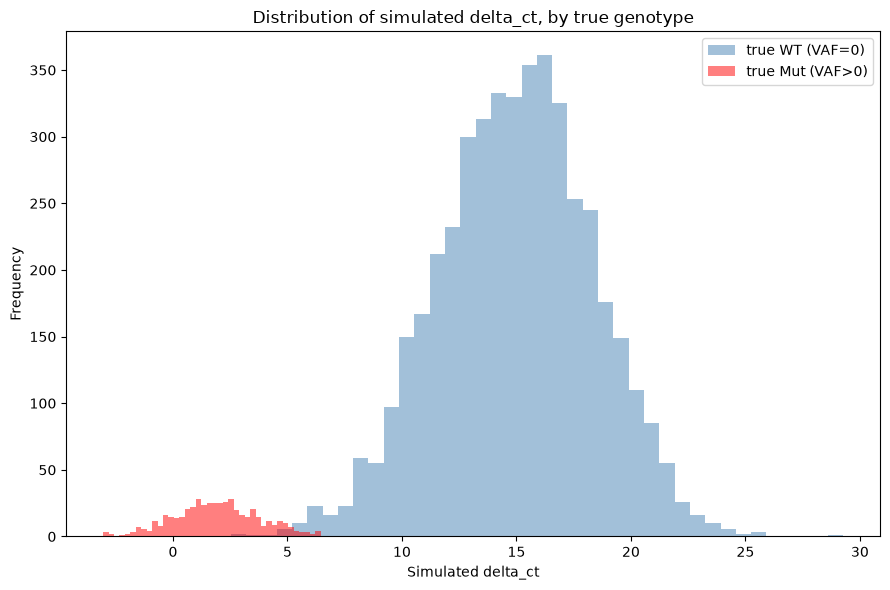


Calibration check - Mut cluster delta_ct (VAF > 0.45):
count    72.000000
mean      0.981032
std       1.593166
min      -3.049395
25%       0.147477
50%       0.948648
75%       1.938072
max       4.157635
Name: delta_ct, dtype: float64

Calibration check - WT cluster delta_ct (VAF == 0):
count    4507.000000
mean       14.973545
std         3.369193
min         2.522402
25%        12.733304
50%        15.055181
75%        17.252782
max        29.262404
Name: delta_ct, dtype: float64

Calibration check - compared to GMM parameters from real dataset


,cluster,real data GMM parameters,synthetic
0,WT - mean,15.2465,14.973545
1,WT - std,3.0852,3.369193
2,Mut - mean (near vaf_max),1.1415,0.981032
3,Mut - std (near vaf_max),1.6598,1.593166


In [5]:
#5: exploration of the generated data & calibration checks
is_wt = df["true_vaf"] == 0
near_vaf_max = 0.9 * PARAMS["vaf_max"]   #samples close to the maximum VAF (0.45 when vaf_max = 0.5)

fig, ax = plt.subplots(figsize=(9, 6))
ax.hist(df.loc[is_wt, "delta_ct"], bins=40, alpha=0.5, color="steelblue", label="true WT (VAF=0)")
ax.hist(df.loc[~is_wt, "delta_ct"], bins=40, alpha=0.5, color="red", label="true Mut (VAF>0)")
ax.set_xlabel("Simulated delta_ct")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of simulated delta_ct, by true genotype")
ax.legend()
plt.tight_layout()
plt.savefig("delta_ct_distribution_synthetic.png", dpi=150)
print("Saved as delta_ct_distribution_synthetic.png")
plt.show()

print(f"\nCalibration check - Mut cluster delta_ct (VAF > {near_vaf_max:g}):")
print(df.loc[df["true_vaf"] > near_vaf_max, "delta_ct"].describe())

print("\nCalibration check - WT cluster delta_ct (VAF == 0):")
print(df.loc[is_wt, "delta_ct"].describe())

print("\nCalibration check - compared to GMM parameters from real dataset")
calibration_summary = pd.DataFrame({
    "cluster": ["WT - mean", "WT - std", "Mut - mean (near vaf_max)", "Mut - std (near vaf_max)"],
    "real data GMM parameters": [PARAMS["background_mean"], PARAMS["real_wt_std"], PARAMS["pure_mutant_delta_ct"], PARAMS["real_mut_std"]], #comparing with the real data parameters
    "synthetic": [
        df.loc[df["true_vaf"] == 0, "delta_ct"].mean(),
        df.loc[df["true_vaf"] == 0, "delta_ct"].std(),
        df.loc[df["true_vaf"] > near_vaf_max, "delta_ct"].mean(),
        df.loc[df["true_vaf"] > near_vaf_max, "delta_ct"].std(),
    ],
})
calibration_summary

Technical failures (Ct_wt >= 38): 2 / 5000
sample_id  ct_wt  ct_mut  delta_ct true_label
 SYN-3656 38.479    50.0    11.521         WT
 SYN-3999 39.816    50.0    10.184         WT

Saved as ct_wt_technical_failure.png


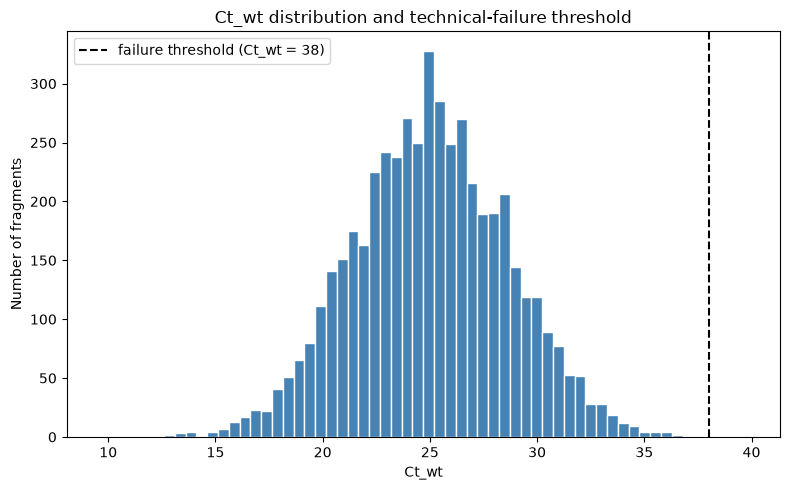

In [6]:
#6: Technical failures QC (based on Ct_wt)
CT_WT_FAILURE = 38.0  #Ct_wt >= this, means the wild-type reaction failed, the fragment cannot be genotyped

df["technical_failure"] = df["ct_wt"] >= CT_WT_FAILURE
print(f"Technical failures (Ct_wt >= {CT_WT_FAILURE:g}): {df['technical_failure'].sum()} / {len(df)}")
print(df.loc[df["technical_failure"], ["sample_id", "ct_wt", "ct_mut", "delta_ct", "true_label"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["ct_wt"], bins=60, color="steelblue", edgecolor="white")
ax.axvline(CT_WT_FAILURE, color="black", linestyle="--", linewidth=1.5, label=f"failure threshold (Ct_wt = {CT_WT_FAILURE:g})")
ax.set_xlabel("Ct_wt")
ax.set_ylabel("Number of fragments")
ax.set_title("Ct_wt distribution and technical-failure threshold")
ax.legend()
plt.tight_layout()
plt.savefig("ct_wt_technical_failure.png", dpi=150)
print("\nSaved as ct_wt_technical_failure.png")
plt.show()

Linear Regression 1, delta_ct ~ logit(VAF), full range:
slope=-1.2486, intercept=2.0838, R^2=0.7959
(theoretically: slope=-1/eff=-1.5385, intercept=pure_mutant_delta_ct=1.1415)

Linear Regression 2, delta_ct ~ logit(VAF), restricted to VAF > 0.01:
slope=-1.6110, intercept=0.9808, R^2=0.6203

Summary for each VAF value (delta_ct mean, std, count across replicates):
    true_vaf       mean       std  count
0   0.000000  14.927036  3.598731     48
1   0.000010  14.999936  2.960798     50
2   0.000012  15.231245  2.690124     50
3   0.000016  14.660946  2.700263     48
4   0.000019  13.966838  2.793736     50
5   0.000024  14.614903  2.697281     50
6   0.000030  14.321127  2.547675     50
7   0.000038  13.999399  2.649174     49
8   0.000047  13.952883  2.642909     50
9   0.000059  14.450879  2.238232     48
10  0.000073  13.771961  2.575889     50
11  0.000091  13.643282  2.402873     50
12  0.000113  13.841148  2.193954     50
13  0.000142  13.698029  2.081396     50
14  0.000176  14.3

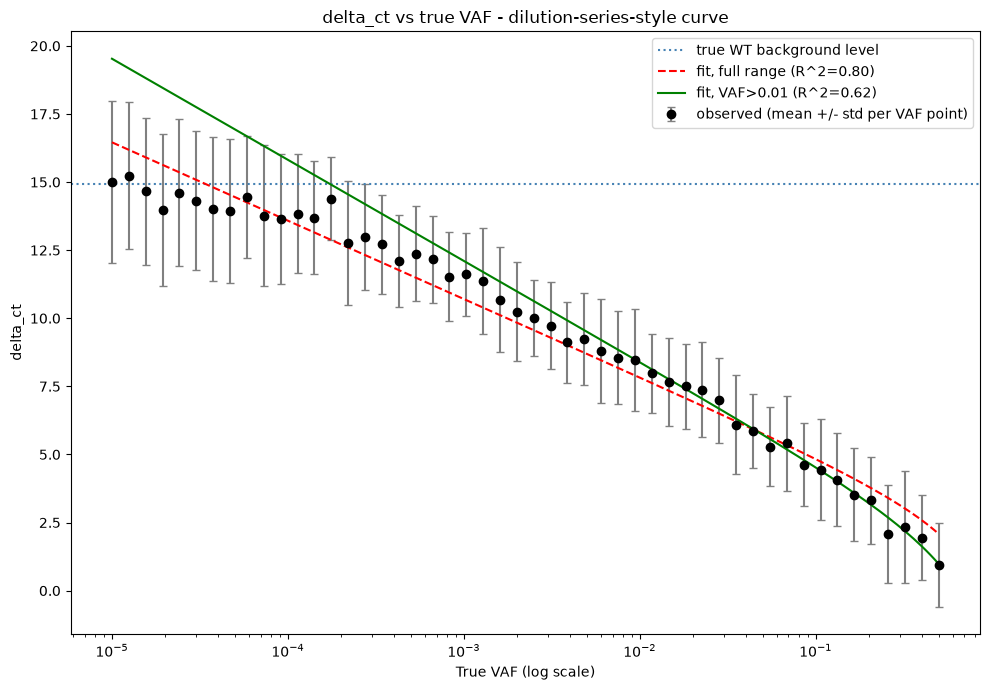

In [7]:
#7: Linear regression between VAF and delta_ct using the VAF sweep
df_sweep = df_sweep.dropna(subset=["delta_ct"]).reset_index(drop=True)

df_signal = df_sweep[df_sweep["true_vaf"] > 0].copy()
df_signal["logit_vaf"] = np.log(df_signal["true_vaf"] / (1 - df_signal["true_vaf"]))


#Linear Regression 1: full range, all VAF>0 grid points
slope_full, intercept_full, r_full, p_full, se_full = stats.linregress(
    df_signal["logit_vaf"], df_signal["delta_ct"]
)
print("Linear Regression 1, delta_ct ~ logit(VAF), full range:")
print(f"slope={slope_full:.4f}, intercept={intercept_full:.4f}, R^2={r_full**2:.4f}")
print(f"(theoretically: slope=-1/eff={-1/PARAMS['eff']:.4f}, intercept=pure_mutant_delta_ct={PARAMS['pure_mutant_delta_ct']})")


#Linear Regression 2: restricted to VAF above a threshold of 0.01, where the signal is expected to dominate over background
threshold = 0.01
df_restricted = df_signal[df_signal["true_vaf"] > threshold]
slope_r, intercept_r, r_r, p_r, se_r = stats.linregress(
    df_restricted["logit_vaf"], df_restricted["delta_ct"]
)
print(f"\nLinear Regression 2, delta_ct ~ logit(VAF), restricted to VAF > {threshold}:")
print(f"slope={slope_r:.4f}, intercept={intercept_r:.4f}, R^2={r_r**2:.4f}")


#Summary of mean, std, count for each true_vaf value in the dataset
grid_summary = df_sweep.groupby("true_vaf")["delta_ct"].agg(["mean", "std", "count"]).reset_index()
print("\nSummary for each VAF value (delta_ct mean, std, count across replicates):")
print(grid_summary)


#Plotting delta_ct vs VAF (log x-axis), observed means with error bars, plus both fitted regression lines
fig, ax = plt.subplots(figsize=(10, 7))

plot_data = grid_summary[grid_summary["true_vaf"] > 0]
ax.errorbar(
    plot_data["true_vaf"], plot_data["mean"], yerr=plot_data["std"],
    fmt="o", color="black", ecolor="gray", capsize=3, label="observed (mean +/- std per VAF point)"
)

wt_point = grid_summary[grid_summary["true_vaf"] == 0]
ax.axhline(wt_point["mean"].values[0], color="steelblue", linestyle=":", label="true WT background level")

x_vaf = np.logspace(np.log10(df_signal["true_vaf"].min()), np.log10(df_signal["true_vaf"].max()), 200)
x_logit = np.log(x_vaf / (1 - x_vaf))
ax.plot(x_vaf, slope_full * x_logit + intercept_full, color="red", linestyle="--",
        label=f"fit, full range (R^2={r_full**2:.2f})")
ax.plot(x_vaf, slope_r * x_logit + intercept_r, color="green",
        label=f"fit, VAF>{threshold} (R^2={r_r**2:.2f})")

ax.set_xscale("log")
ax.set_xlabel("True VAF (log scale)")
ax.set_ylabel("delta_ct")
ax.set_title("delta_ct vs true VAF - dilution-series-style curve")
ax.legend()
plt.tight_layout()
plt.savefig("linear_regression_curve.png", dpi=150)
print("\nSaved as linear_regression_curve.png")
plt.show()

Random Forest regressor, delta_ct ~ log10(VAF):
Test R^2: 0.8112
Test RMSE: 1.9598

Linear regression curve (for comparison): slope=-1.2486, intercept=2.0838, R^2=0.7959

Saved as rf_linreg_comparison.png


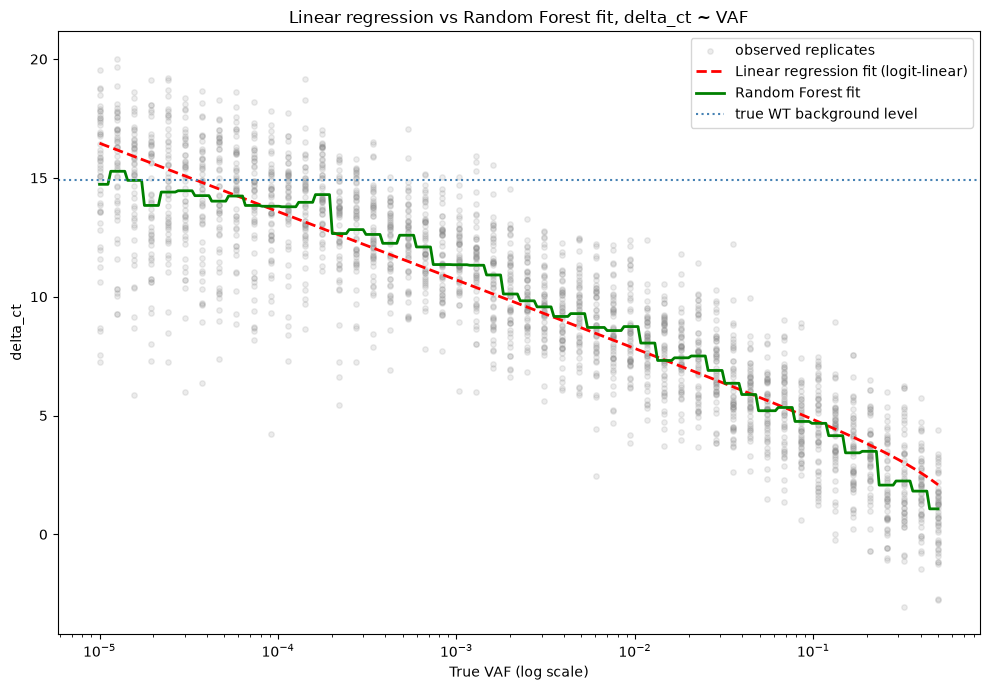

In [8]:
#8: VAF random forest nonlinear regressor
df_signal = df_sweep[df_sweep["true_vaf"] > 0].copy()
df_signal["log_vaf"] = np.log10(df_signal["true_vaf"])

X = df_signal[["log_vaf"]].values
y = df_signal["delta_ct"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rf = RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=10, random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
print("Random Forest regressor, delta_ct ~ log10(VAF):")
print(f"Test R^2: {r2_score(y_test, y_pred):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

#Linear regression (full range), for comparison
df_signal["logit_vaf"] = np.log(df_signal["true_vaf"] / (1 - df_signal["true_vaf"]))
lin_slope, lin_intercept, r, p, se = stats.linregress(df_signal["logit_vaf"], df_signal["delta_ct"])
print(f"\nLinear regression curve (for comparison): slope={lin_slope:.4f}, intercept={lin_intercept:.4f}, R^2={r**2:.4f}")


#Predicting across a smooth VAF grid for plotting
vaf_grid = np.logspace(np.log10(df_signal["true_vaf"].min()), np.log10(df_signal["true_vaf"].max()), 300)
log_vaf_grid = np.log10(vaf_grid).reshape(-1, 1)
rf_curve = rf.predict(log_vaf_grid)

logit_grid = np.log(vaf_grid / (1 - vaf_grid))
linear_regression_curve = lin_slope * logit_grid + lin_intercept

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(df_signal["true_vaf"], df_signal["delta_ct"], alpha=0.15, color="gray", s=15, label="observed replicates")
ax.plot(vaf_grid, linear_regression_curve, color="red", linestyle="--", linewidth=2, label="Linear regression fit (logit-linear)")
ax.plot(vaf_grid, rf_curve, color="green", linewidth=2, label="Random Forest fit")
sweep_wt_mean = df_sweep.loc[df_sweep["true_vaf"] == 0, "delta_ct"].mean()
ax.axhline(sweep_wt_mean, color="steelblue", linestyle=":", label="true WT background level")
ax.set_xscale("log")
ax.set_xlabel("True VAF (log scale)")
ax.set_ylabel("delta_ct")
ax.set_title("Linear regression vs Random Forest fit, delta_ct ~ VAF")
ax.legend()
plt.tight_layout()
plt.savefig("rf_linreg_comparison.png", dpi=150)
print("\nSaved as rf_linreg_comparison.png")
plt.show()

ct_wt ~ log10_conc linear regression: slope=0.0950, R^2=0.0001, p=0.4259

Summary statistics for the 3 PCA input variables (before standardization):
            ct_mut   log10_conc  ct_wt_residual
count  5000.000000  5000.000000    5.000000e+03
mean     38.703433     1.871920    1.506351e-16
std       6.162569     0.431147    3.637536e+00
min      15.659212     1.114014   -1.544408e+01
25%      35.216913     1.498135   -2.462661e+00
50%      39.313736     1.869064   -2.172673e-02
75%      43.028760     2.246798    2.459184e+00
max      50.000000     2.614833    1.476135e+01

PCA variance breakdown:
Explained variance ratio per principal component (PC1, PC2, PC3): [0.5409 0.3333 0.1258]
Cumulative explained variance: [0.5409 0.8742 1.    ]

Loadings of each original variable on each principal component:
                   PC1     PC2     PC3
ct_mut          0.7071 -0.0000  0.7071
log10_conc     -0.2815  0.9173  0.2815
ct_wt_residual  0.6487  0.3981 -0.6487
Saved as pca_synthetic.csv

Sa

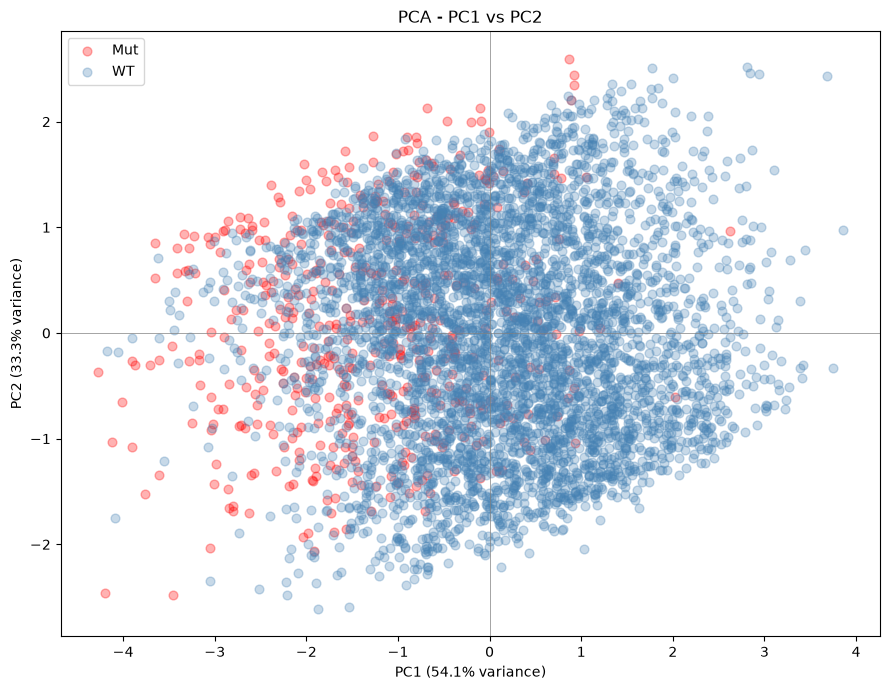


Saved as pca_pc1pc3.png


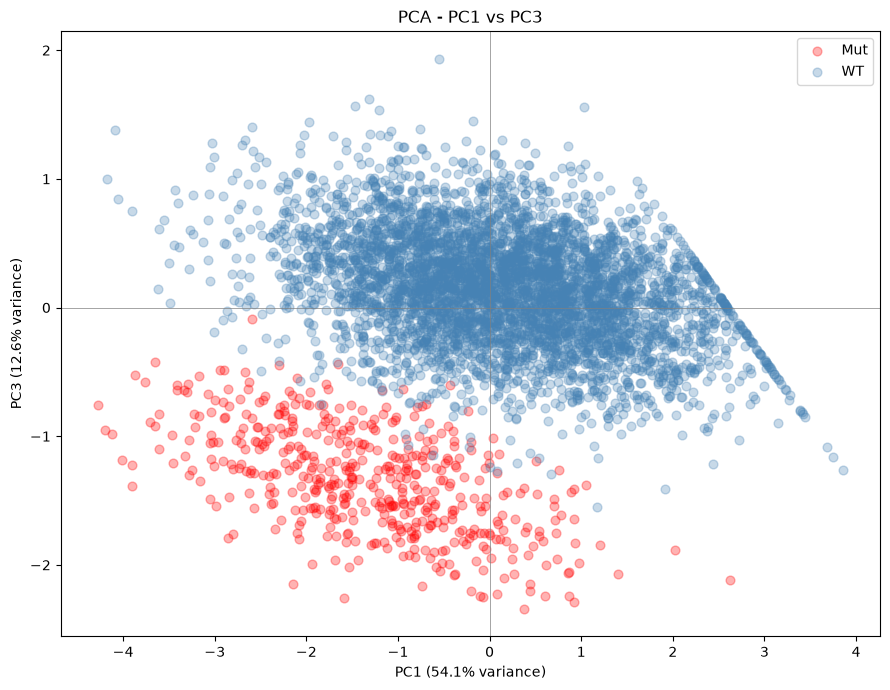


Saved as pca_pc2pc3.png


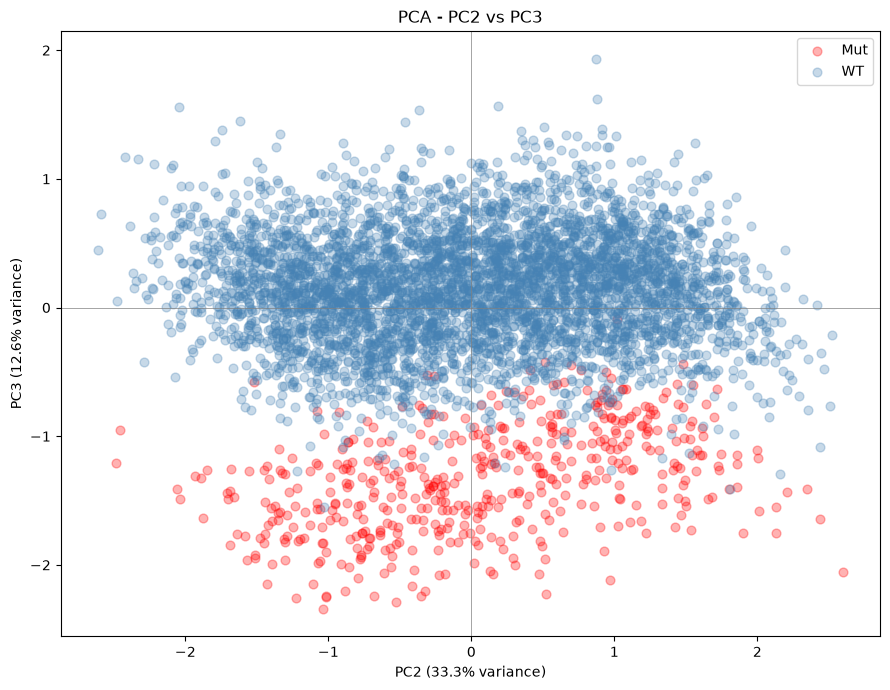

In [9]:
#9: PCA
df["log10_conc"] = np.log10(df["dna_conc"])

#ct_wt_residual (as a proxy for quality), obtained from the linear regression of ct_wt ~ log10_conc
slope_wt, intercept_wt, r_wt, p_wt, se_wt = stats.linregress(df["log10_conc"], df["ct_wt"])
print(f"ct_wt ~ log10_conc linear regression: slope={slope_wt:.4f}, R^2={r_wt**2:.4f}, p={p_wt:.4f}")
df["ct_wt_predicted"] = slope_wt * df["log10_conc"] + intercept_wt
df["ct_wt_residual"] = df["ct_wt"] - df["ct_wt_predicted"]

#feature matrix
features = df[["ct_mut", "log10_conc", "ct_wt_residual"]].copy()
print("\nSummary statistics for the 3 PCA input variables (before standardization):")
print(features.describe())

#standardize and fit PCA
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)
pca = PCA()
pca_result = pca.fit_transform(features_scaled)
print("\nPCA variance breakdown:")
print("Explained variance ratio per principal component (PC1, PC2, PC3):", np.round(pca.explained_variance_ratio_, 4))
print("Cumulative explained variance:", np.round(np.cumsum(pca.explained_variance_ratio_), 4))

#loadings of each original variable on each principal component
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2", "PC3"],
    index=["ct_mut", "log10_conc", "ct_wt_residual"]
)
print("\nLoadings of each original variable on each principal component:")
print(loadings.round(4))


df["PC1"] = pca_result[:, 0]
df["PC2"] = pca_result[:, 1]
df["PC3"] = pca_result[:, 2]

df.to_csv("pca_synthetic.csv", index=False)
print("Saved as pca_synthetic.csv")


#PC1 vs PC2 biplot, colored by true genotype
fig, ax = plt.subplots(figsize=(9, 7))
colors = {"Mut": "red", "WT": "steelblue"}
for label, group in df.groupby("true_label"):
    ax.scatter(group["PC1"], group["PC2"], label=label, color=colors[label], alpha=0.3, s=40)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.set_title("PCA - PC1 vs PC2")
ax.legend()
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
plt.tight_layout()
plt.savefig("pca_pc1pc2.png", dpi=150)
print("\nSaved as pca_pc1pc2.png")
plt.show()

#PC1 vs PC3 biplot
fig, ax = plt.subplots(figsize=(9, 7))
colors = {"Mut": "red", "WT": "steelblue"}
for label, group in df.groupby("true_label"):
    ax.scatter(group["PC1"], group["PC3"], label=label, color=colors[label], alpha=0.3, s=40)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}% variance)")
ax.set_title("PCA - PC1 vs PC3")
ax.legend()
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
plt.tight_layout()
plt.savefig("pca_pc1pc3.png", dpi=150)
print("\nSaved as pca_pc1pc3.png")
plt.show()

#PC2 vs PC3 biplot
fig, ax = plt.subplots(figsize=(9, 7))
colors = {"Mut": "red", "WT": "steelblue"}
for label, group in df.groupby("true_label"):
    ax.scatter(group["PC2"], group["PC3"], label=label, color=colors[label], alpha=0.3, s=40)
ax.set_xlabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.set_ylabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}% variance)")
ax.set_title("PCA - PC2 vs PC3")
ax.legend()
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
plt.tight_layout()
plt.savefig("pca_pc2pc3.png", dpi=150)
print("\nSaved as pca_pc2pc3.png")
plt.show()

GMM with 2 components:
Component means: [ 2.121 15.025]
Component variances: [ 4.09  10.949]
Component weights: [0.104 0.896]

BIC sweep, k=1 to 5:
k=1: BIC=30443.92
k=2: BIC=28856.55
k=3: BIC=28894.65
k=4: BIC=28935.32
k=5: BIC=28966.51
Best k according to BIC: 2
Saved as bic_sweep_synthetic.png


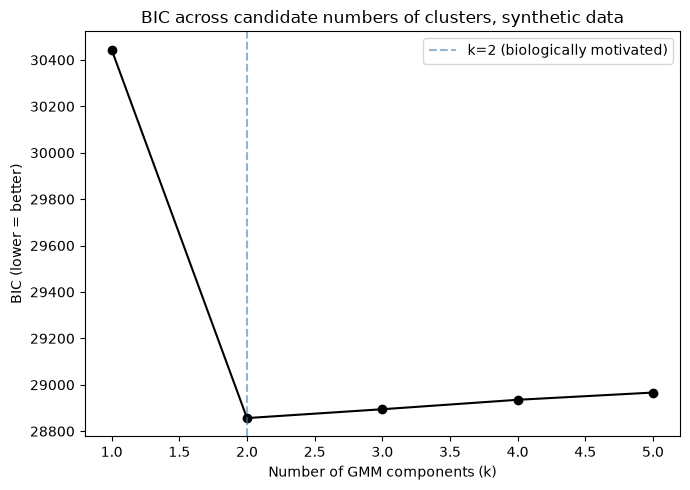


GMM vs true genotype:
Accuracy: 0.9928

Confusion matrix:
[[ 488    5]
 [  31 4476]]

Classification report:
              precision    recall  f1-score   support

         Mut       0.94      0.99      0.96       493
          WT       1.00      0.99      1.00      4507

    accuracy                           0.99      5000
   macro avg       0.97      0.99      0.98      5000
weighted avg       0.99      0.99      0.99      5000


Misclassified:
     sample_id  true_vaf  delta_ct true_label gmm_label
23    SYN-0023  0.000000  5.487861         WT       Mut
37    SYN-0037  0.000000  6.106089         WT       Mut
137   SYN-0137  0.000000  5.689028         WT       Mut
181   SYN-0181  0.000000  4.720927         WT       Mut
320   SYN-0320  0.398024  6.350180        Mut        WT
390   SYN-0390  0.000000  5.056552         WT       Mut
816   SYN-0816  0.000000  5.339041         WT       Mut
919   SYN-0919  0.000000  5.085210         WT       Mut
1025  SYN-1025  0.000000  6.000006         

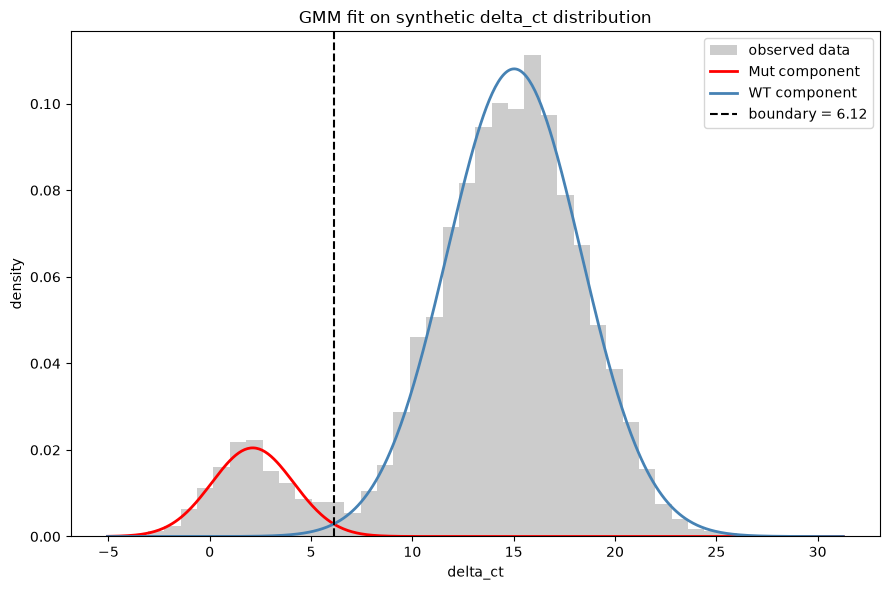

Saved as gmm_classified_synthetic.csv


In [10]:
#10: GMM
X = df["delta_ct"].values.reshape(-1, 1)

#GMM with 2 components
gmm2 = GaussianMixture(n_components=2, random_state=42)
gmm2.fit(X)

print("GMM with 2 components:")
print("Component means:", np.round(gmm2.means_.ravel(), 3))
print("Component variances:", np.round(gmm2.covariances_.ravel(), 3))
print("Component weights:", np.round(gmm2.weights_, 3))

mutant_component = np.argmin(gmm2.means_.ravel())
cluster_labels = gmm2.predict(X)
df["gmm_label"] = np.where(cluster_labels == mutant_component, "Mut", "WT")

#fitted GMM parameters
mut_mean = gmm2.means_.ravel()[mutant_component]
mut_var = gmm2.covariances_.ravel()[mutant_component]
mut_weight = gmm2.weights_[mutant_component]
wt_mean = gmm2.means_.ravel()[1 - mutant_component]
wt_var = gmm2.covariances_.ravel()[1 - mutant_component]
wt_weight = gmm2.weights_[1 - mutant_component]


#BIC sweep for k=1 to 5
print("\nBIC sweep, k=1 to 5:")
bic_scores = []
for k in range(1, 6):
    gmm_k = GaussianMixture(n_components=k, random_state=42)
    gmm_k.fit(X)
    score = gmm_k.bic(X)
    bic_scores.append(score)
    print(f"k={k}: BIC={score:.2f}")
best_k = np.argmin(bic_scores) + 1
print(f"Best k according to BIC: {best_k}")

#plotting BIC scores
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(range(1, 6), bic_scores, marker="o", color="black")
ax.axvline(2, color="steelblue", linestyle="--", alpha=0.6, label="k=2 (biologically motivated)")
ax.set_xlabel("Number of GMM components (k)")
ax.set_ylabel("BIC (lower = better)")
ax.set_title("BIC across candidate numbers of clusters, synthetic data")
ax.legend()
plt.tight_layout()
plt.savefig("bic_sweep_synthetic.png", dpi=150)
print("Saved as bic_sweep_synthetic.png")
plt.show()


#GMM accuracy against true genotype
print("\nGMM vs true genotype:")
print(f"Accuracy: {accuracy_score(df['true_label'], df['gmm_label']):.4f}")
print("\nConfusion matrix:")
print(confusion_matrix(df["true_label"], df["gmm_label"], labels=["Mut", "WT"]))
print("\nClassification report:")
print(classification_report(df["true_label"], df["gmm_label"]))
print("\nMisclassified:")
misclassified = df[df["true_label"] != df["gmm_label"]]
print(misclassified[["sample_id", "true_vaf", "delta_ct", "true_label", "gmm_label"]])

#GMM decision boundary: where the weighted component densities cross (P(Mut) = 0.5)
x_search = np.linspace(mut_mean, wt_mean, 10000)
dens_mut = mut_weight * norm.pdf(x_search, mut_mean, np.sqrt(mut_var))
dens_wt = wt_weight * norm.pdf(x_search, wt_mean, np.sqrt(wt_var))
gmm_boundary = x_search[np.argmin(np.abs(dens_mut - dens_wt))]
print(f"\nGMM decision boundary: delta_ct = {gmm_boundary:.3f}")

#Distribution plot with fitted GMM components overlaid
fig, ax = plt.subplots(figsize=(9, 6))
ax.hist(df["delta_ct"], bins=40, density=True, alpha=0.4, color="gray", label="observed data")

x_range = np.linspace(df["delta_ct"].min() - 2, df["delta_ct"].max() + 2, 500)
component_info = [
    ("Mut component", "red", mutant_component),
    ("WT component", "steelblue", 1 - mutant_component),
]
for label, color, comp_idx in component_info:
    mean = gmm2.means_.ravel()[comp_idx]
    std = np.sqrt(gmm2.covariances_.ravel()[comp_idx])
    weight = gmm2.weights_[comp_idx]
    curve = weight * norm.pdf(x_range, mean, std)
    ax.plot(x_range, curve, color=color, linewidth=2, label=label)

ax.axvline(gmm_boundary, color="black", linestyle="--", label=f"boundary = {gmm_boundary:.2f}")
ax.set_xlabel("delta_ct")
ax.set_ylabel("density")
ax.set_title("GMM fit on synthetic delta_ct distribution")
ax.legend()
plt.tight_layout()
plt.savefig("gmm_fit_synthetic.png", dpi=150)
print("\nSaved as gmm_fit_synthetic.png")
plt.show()

df.to_csv("gmm_classified_synthetic.csv", index=False)
print("Saved as gmm_classified_synthetic.csv")

Supervised class densities + stated prior, vs unsupervised GMM (current PARAMS prevalence = 10%):

 prevalence  n_mut_train  boundary  sensitivity  specificity   PPV  GMM_mut_mean  GMM_mut_weight
       0.50         2455     6.659        0.997        0.994 0.994         1.883           0.500
       0.40         1951     6.470        0.995        0.995 0.992         1.888           0.399
       0.30         1472     6.305        0.993        0.995 0.988         1.935           0.303
       0.25         1240     6.161        0.992        0.996 0.988         1.932           0.256
       0.20          984     6.085        0.990        0.996 0.985         1.981           0.204
       0.14          681     5.908        0.988        0.997 0.981         2.044           0.143
       0.10          493     5.729        0.987        0.997 0.977         2.099           0.106
       0.05          243     5.224        0.973        0.998 0.969         9.958           0.206
       0.03          156    

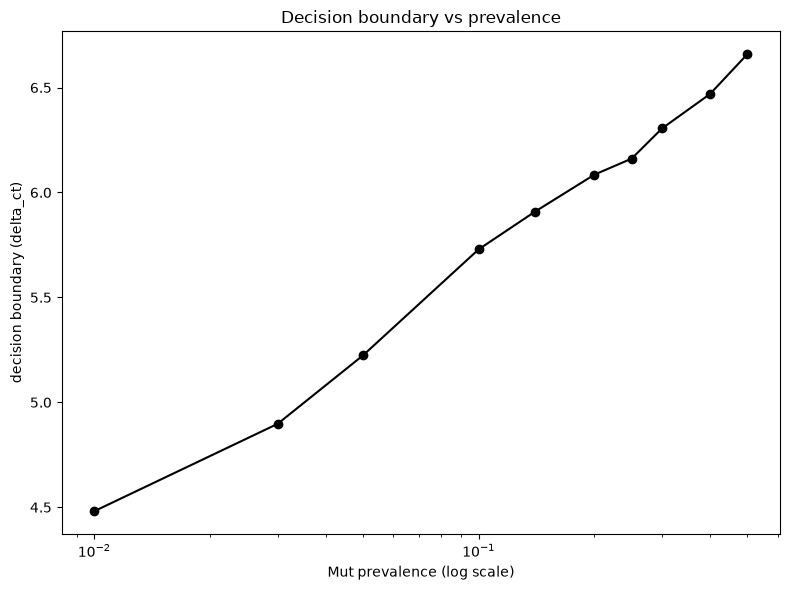


Saved as prevalence_performance.png


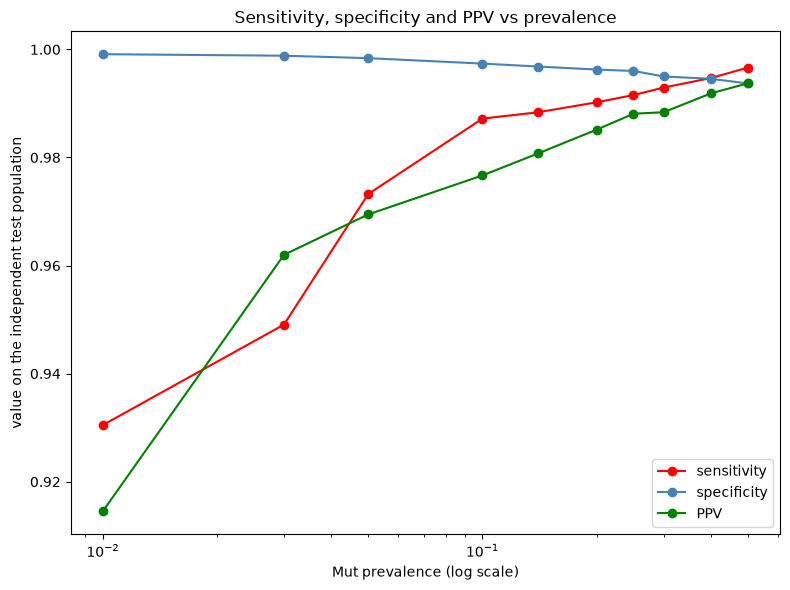

In [11]:
#11: Prevalence scenarios - class-conditional densities fitted on the true labels, prior set explicitly
"""The unsupervised GMM has to find the Mut cluster by itself, and it learns the Mut weight from the sample.
Since in this simulation the true labels are known, here each class gets its own normal density, and the prior
(the prevalence) is stated instead of learned. The boundary is where prior_mut * f_mut(x) = (1 - prior_mut) * f_wt(x).
For every prevalence a new population is generated at that prevalence (training set), and sensitivity, specificity and PPV
are measured on a second, independent population (test set)."""


def make_dataset(prevalence, n, seed):
    d = generate_synthetic_qpcr_data(n, **{**GEN_KWARGS, "p_wt": 1 - prevalence, "random_seed": seed})
    d = d.dropna(subset=["delta_ct"]).reset_index(drop=True)
    d["is_mut"] = d["true_vaf"] > 0
    return d


def bayes_boundary(prior_mut, mut_mean, mut_sd, wt_mean, wt_sd):
    """delta_ct where the prior-weighted Mut and WT densities are equal, searched between the two class means"""
    f = lambda t: prior_mut * norm.pdf(t, mut_mean, mut_sd) - (1 - prior_mut) * norm.pdf(t, wt_mean, wt_sd)
    return brentq(f, mut_mean, wt_mean)


PREVALENCE_GRID = sorted(set([0.50, 0.40, 0.30, 0.25, 0.20, 0.14, 0.10, 0.05, 0.03, 0.01, PARAMS["prevalence_mut"]]), reverse=True)

rows = []
for prev in PREVALENCE_GRID:
    train = make_dataset(prev, 5000, seed=42)
    test = make_dataset(prev, 20000, seed=7)

    #supervised: one normal density per class, fitted on the true labels
    mut_x = train.loc[train["is_mut"], "delta_ct"]
    wt_x = train.loc[~train["is_mut"], "delta_ct"]
    boundary = bayes_boundary(prev, mut_x.mean(), mut_x.std(), wt_x.mean(), wt_x.std())

    #performance on the independent test population
    sens = (test.loc[test["is_mut"], "delta_ct"] < boundary).mean()
    spec = (test.loc[~test["is_mut"], "delta_ct"] >= boundary).mean()
    ppv = prev * sens / (prev * sens + (1 - prev) * (1 - spec))

    #unsupervised GMM on the same training data (no labels), for comparison
    gmm_p = GaussianMixture(n_components=2, random_state=42).fit(train[["delta_ct"]].values)
    k = np.argmin(gmm_p.means_.ravel())

    rows.append({
        "prevalence": prev, "n_mut_train": int(train["is_mut"].sum()),
        "boundary": boundary, "sensitivity": sens, "specificity": spec, "PPV": ppv,
        "GMM_mut_mean": gmm_p.means_.ravel()[k], "GMM_mut_weight": gmm_p.weights_[k],
    })

prevalence_table = pd.DataFrame(rows)
print(f"Supervised class densities + stated prior, vs unsupervised GMM (current PARAMS prevalence = {PARAMS['prevalence_mut']:.0%}):\n")
print(prevalence_table.round(3).to_string(index=False))
print("\nThe unsupervised GMM is correct only while its Mut mean stays near the true Mut cluster and its Mut weight near the prevalence.")

#plot 1: decision boundary as a function of prevalence
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(prevalence_table["prevalence"], prevalence_table["boundary"], marker="o", color="black")
ax.set_xscale("log")
ax.set_xlabel("Mut prevalence (log scale)")
ax.set_ylabel("decision boundary (delta_ct)")
ax.set_title("Decision boundary vs prevalence")
plt.tight_layout()
plt.savefig("prevalence_boundary.png", dpi=150)
print("\nSaved as prevalence_boundary.png")
plt.show()

#plot 2: sensitivity, specificity and PPV as a function of prevalence
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(prevalence_table["prevalence"], prevalence_table["sensitivity"], marker="o", color="red", label="sensitivity")
ax.plot(prevalence_table["prevalence"], prevalence_table["specificity"], marker="o", color="steelblue", label="specificity")
ax.plot(prevalence_table["prevalence"], prevalence_table["PPV"], marker="o", color="green", label="PPV")
ax.set_xscale("log")
ax.set_xlabel("Mut prevalence (log scale)")
ax.set_ylabel("value on the independent test population")
ax.set_title("Sensitivity, specificity and PPV vs prevalence")
ax.legend()
plt.tight_layout()
plt.savefig("prevalence_performance.png", dpi=150)
print("\nSaved as prevalence_performance.png")
plt.show()

Supervised benchmark vs initialised GMM vs plain GMM:

             accuracy                      mut_mean                    mut_weight                   
           supervised init GMM plain GMM supervised init GMM plain GMM supervised init GMM plain GMM
prevalence                                                                                          
0.50            0.995    0.995     0.995      1.854    1.880     1.883       0.50    0.500     0.500
0.40            0.995    0.995     0.995      1.856    1.888     1.888       0.40    0.399     0.399
0.30            0.994    0.995     0.995      1.885    1.934     1.935       0.30    0.303     0.303
0.25            0.995    0.995     0.994      1.873    1.930     1.932       0.25    0.256     0.256
0.20            0.995    0.995     0.995      1.910    1.976     1.981       0.20    0.204     0.204
0.14            0.996    0.995     0.995      1.922    2.054     2.044       0.14    0.144     0.143
0.10            0.996    0.996     0

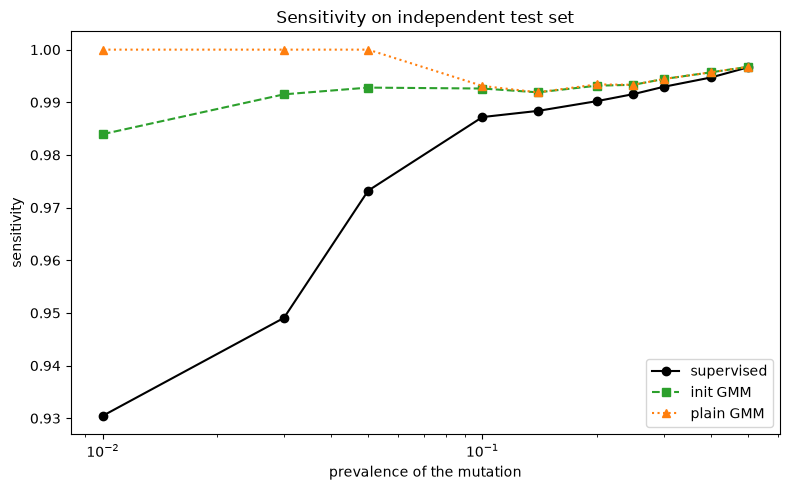


Saved as gmm_vs_supervised_specificity.png


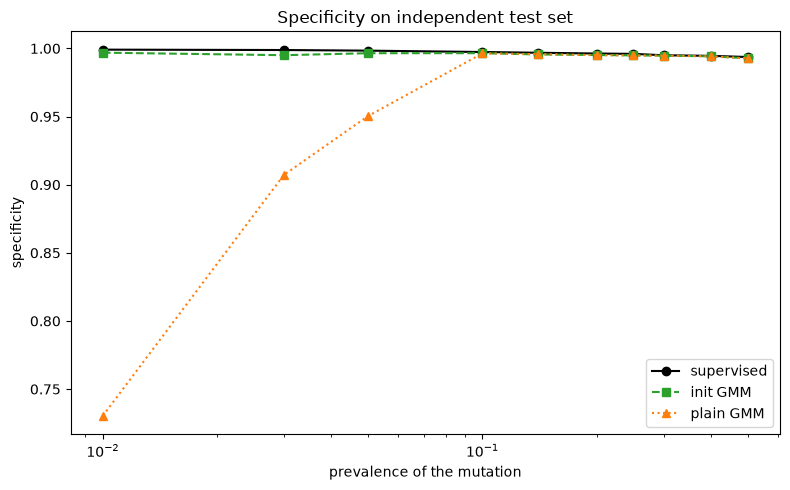


Saved as gmm_vs_supervised_mutmean.png


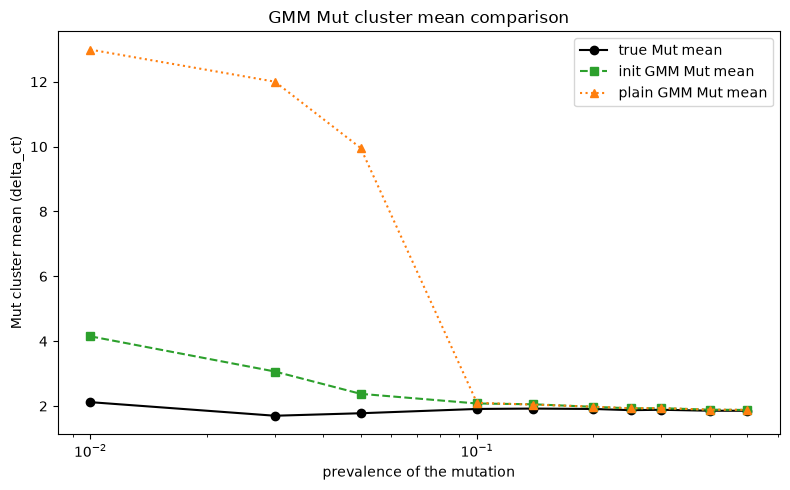

In [12]:
#12: plain GMM vs initialised GMM (both unsupervised) vs supervised benchmark, across prevalence

rows = []
for prev in PREVALENCE_GRID:
    train = make_dataset(prev, 5000, seed=42)
    test = make_dataset(prev, 20000, seed=7)
    y_test = test["is_mut"].values

    #supervised benchmark: class densities fitted on the true labels + the stated prior
    mut_x = train.loc[train["is_mut"], "delta_ct"]
    wt_x = train.loc[~train["is_mut"], "delta_ct"]
    boundary = bayes_boundary(prev, mut_x.mean(), mut_x.std(), wt_x.mean(), wt_x.std())
    sup_pred = test["delta_ct"].values < boundary
    results = {"supervised": (sup_pred, mut_x.mean(), prev)}

    #two unsupervised GMMs, no labels: plain (default start) and initialised (with the real data means + prevalence as weights)
    gmm_settings = {
        "plain GMM": {},
        "init GMM": {"means_init": [[PARAMS["pure_mutant_delta_ct"]], [PARAMS["background_mean"]]],
                     "weights_init": [prev, 1 - prev]},
    }
    for name, init in gmm_settings.items():
        g = GaussianMixture(n_components=2, random_state=42, **init).fit(train[["delta_ct"]].values)
        k = np.argmin(g.means_.ravel())
        results[name] = (g.predict(test[["delta_ct"]].values) == k, g.means_.ravel()[k], g.weights_[k])

    for name, (pred, mut_mean_m, mut_weight_m) in results.items():
        rows.append({
            "prevalence": prev, "method": name,
            "sensitivity": pred[y_test].mean(),
            "specificity": (~pred[~y_test]).mean(),
            "accuracy": (pred == y_test).mean(),
            "mut_mean": mut_mean_m, "mut_weight": mut_weight_m,
        })

compare_table = pd.DataFrame(rows)
METHODS = ["supervised", "init GMM", "plain GMM"]
wide = compare_table.pivot(index="prevalence", columns="method").sort_index(ascending=False)
print("Supervised benchmark vs initialised GMM vs plain GMM:\n")
print(wide[["accuracy", "mut_mean", "mut_weight"]].round(3)
      .reindex(columns=pd.MultiIndex.from_product([["accuracy", "mut_mean", "mut_weight"], METHODS])).to_string())

for name in ["init GMM", "plain GMM"]:
    gap = wide["accuracy"]["supervised"] - wide["accuracy"][name]
    print(f"Largest accuracy gap to the benchmark, {name}: {gap.max():.4f} (at prevalence {gap.idxmax():.0%})")

STYLES = {"supervised": ("-o", "black"), "init GMM": ("--s", "tab:green"), "plain GMM": (":^", "tab:orange")}

#plot 1: sensitivity, all methods
fig, ax = plt.subplots(figsize=(8, 5))
for name in METHODS:
    sub = compare_table[compare_table["method"] == name].sort_values("prevalence")
    style, color = STYLES[name]
    ax.plot(sub["prevalence"], sub["sensitivity"], style, color=color, label=name)
ax.set_xscale("log")
ax.set_xlabel("prevalence of the mutation")
ax.set_ylabel("sensitivity")
ax.set_title("Sensitivity on independent test set")
ax.legend()
plt.tight_layout()
plt.savefig("gmm_vs_supervised_sensitivity.png", dpi=150)
print("\nSaved as gmm_vs_supervised_sensitivity.png")
plt.show()

#plot 2: specificity, all methods
fig, ax = plt.subplots(figsize=(8, 5))
for name in METHODS:
    sub = compare_table[compare_table["method"] == name].sort_values("prevalence")
    style, color = STYLES[name]
    ax.plot(sub["prevalence"], sub["specificity"], style, color=color, label=name)
ax.set_xscale("log")
ax.set_xlabel("prevalence of the mutation")
ax.set_ylabel("specificity")
ax.set_title("Specificity on independent test set")
ax.legend()
plt.tight_layout()
plt.savefig("gmm_vs_supervised_specificity.png", dpi=150)
print("\nSaved as gmm_vs_supervised_specificity.png")
plt.show()

#plot 3: where each GMM puts the Mut cluster mean, vs the true Mut cluster mean
fig, ax = plt.subplots(figsize=(8, 5))
for name in METHODS:
    sub = compare_table[compare_table["method"] == name].sort_values("prevalence")
    style, color = STYLES[name]
    ax.plot(sub["prevalence"], sub["mut_mean"], style, color=color, label="true Mut mean" if name == "supervised" else f"{name} Mut mean")
ax.set_xscale("log")
ax.set_xlabel("prevalence of the mutation")
ax.set_ylabel("Mut cluster mean (delta_ct)")
ax.set_title("GMM Mut cluster mean comparison")
ax.legend()
plt.tight_layout()
plt.savefig("gmm_vs_supervised_mutmean.png", dpi=150)
print("\nSaved as gmm_vs_supervised_mutmean.png")
plt.show()

Calibration curve (predicted probability vs observed frequency):
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.000  observed=0.000
predicted=0.096  observed=0.040
predicted=0.960  observed=0.932
predicted=0.999  observed=1.000

Brier score: 0.00461  (0 = perfect, 0.25 = no better than always predicting 0.5)

Saved as gmm_calibration_curve.png


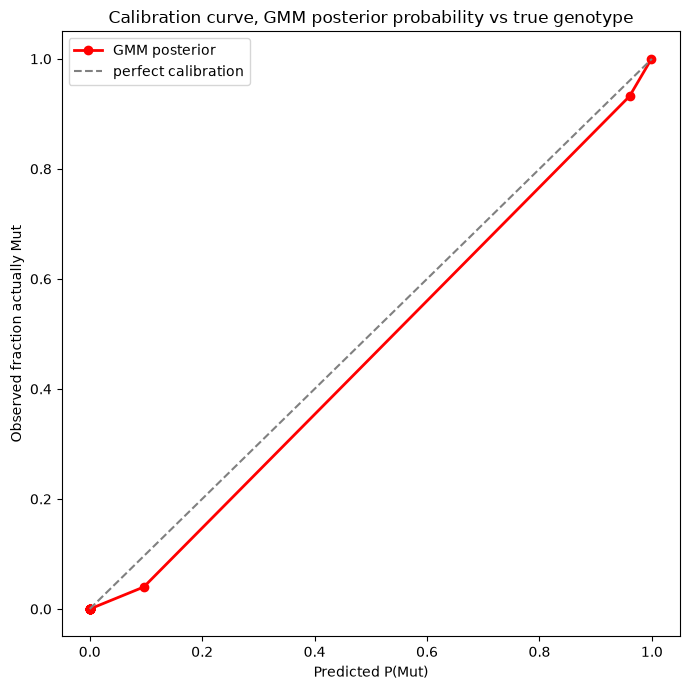

In [13]:
#13: Calibration curve for the GMM classifier
"""Comparing the predicted probabilities of the classifier to the actual observed frequencies"""

def posterior_mut_prob(delta_ct):
    """P(Mut | delta_ct) - posterior probability of a sample being mutant given its delta_ct value, 
    according to the already fitted GMM"""
    density_mut = mut_weight * norm.pdf(delta_ct, mut_mean, np.sqrt(mut_var))
    density_wt = wt_weight * norm.pdf(delta_ct, wt_mean, np.sqrt(wt_var))
    return density_mut / (density_mut + density_wt)

df["p_mut"] = posterior_mut_prob(df["delta_ct"].values)

"""Calibration curve - bin by predicted probability, compare to actual fraction Mut in each bin. 
We divide the probability range [0, 1] into 20 bins.
The bins are chosen so that each one contains approximately the same number of samples (strategy="quantile")
"""
prob_true, prob_pred = calibration_curve(
    df["true_label_binary"], df["p_mut"], n_bins=20, strategy="quantile"
)

print("Calibration curve (predicted probability vs observed frequency):")
for pt, pp in zip(prob_pred, prob_true):
    print(f"predicted={pt:.3f}  observed={pp:.3f}")

brier = brier_score_loss(df["true_label_binary"], df["p_mut"])
print(f"\nBrier score: {brier:.5f}  (0 = perfect, 0.25 = no better than always predicting 0.5)")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(prob_pred, prob_true, marker="o", color="red", linewidth=2, label="GMM posterior")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="perfect calibration")
ax.set_xlabel("Predicted P(Mut)")
ax.set_ylabel("Observed fraction actually Mut")
ax.set_title("Calibration curve, GMM posterior probability vs true genotype")
ax.legend()
plt.tight_layout()
plt.savefig("gmm_calibration_curve.png", dpi=150)
print("\nSaved as gmm_calibration_curve.png")
plt.show()

Already fitted on the sample dataset GMM Classifier:
Mut component: mean=2.121, std=2.022, weight=0.104
WT component: mean=15.025, std=3.309, weight=0.896

Specificity: 1.0000, n=48 true WT correctly classified as WT

Sensitivity by VAF level:
    true_vaf  sensitivity   n
0   0.000010     0.000000  50
1   0.000012     0.000000  50
2   0.000016     0.020833  48
3   0.000019     0.000000  50
4   0.000024     0.000000  50
5   0.000030     0.020000  50
6   0.000038     0.000000  49
7   0.000047     0.000000  50
8   0.000059     0.000000  48
9   0.000073     0.000000  50
10  0.000091     0.020000  50
11  0.000113     0.000000  50
12  0.000142     0.000000  50
13  0.000176     0.000000  50
14  0.000220     0.020000  50
15  0.000274     0.000000  50
16  0.000342     0.000000  50
17  0.000427     0.000000  50
18  0.000532     0.000000  50
19  0.000664     0.000000  50
20  0.000828     0.000000  50
21  0.001032     0.020000  50
22  0.001287     0.020000  50
23  0.001606     0.000000  50
24  0.

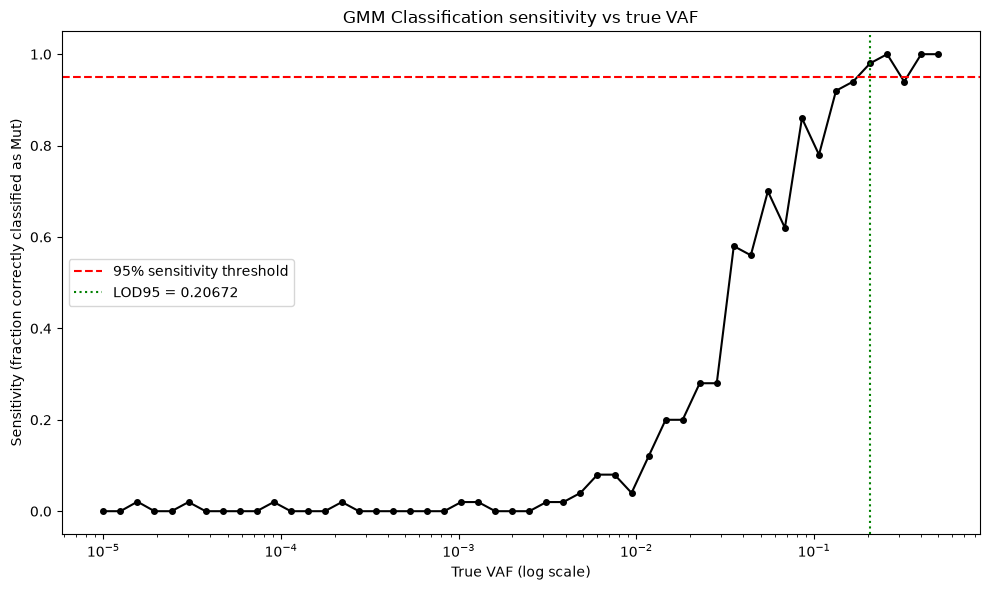

In [14]:
#14: sensitivity analysis (GMM classifier)
"""Determining the limit of detection (LOD) of the qPCR assay, model-implied sensitivity"""

print("Already fitted on the sample dataset GMM Classifier:")
print(f"Mut component: mean={mut_mean:.3f}, std={np.sqrt(mut_var):.3f}, weight={mut_weight:.3f}")
print(f"WT component: mean={wt_mean:.3f}, std={np.sqrt(wt_var):.3f}, weight={wt_weight:.3f}")


def classify(delta_ct):
    """GMM posterior probabilities-based classification: Mut if P(Mut | delta_ct) > 0.5"""
    density_mut = mut_weight * norm.pdf(delta_ct, mut_mean, np.sqrt(mut_var))
    density_wt = wt_weight * norm.pdf(delta_ct, wt_mean, np.sqrt(wt_var))
    return np.where(density_mut > density_wt, "Mut", "WT")


#Applying the same classifier to the sweep dataset
df_sweep["predicted_label"] = classify(df_sweep["delta_ct"].values)

#Specificity
wt_reference = df_sweep[df_sweep["true_vaf"] == 0]
specificity = (wt_reference["predicted_label"] == "WT").mean()
print(f"\nSpecificity: {specificity:.4f}, n={len(wt_reference)} true WT correctly classified as WT")


#Sensitivity for each VAF grid point
mut_points = df_sweep[df_sweep["true_vaf"] > 0].copy()
sensitivity_by_vaf = mut_points.groupby("true_vaf").apply(
    lambda g: (g["predicted_label"] == "Mut").mean()
).reset_index(name="sensitivity")
sensitivity_by_vaf["n"] = mut_points.groupby("true_vaf").size().values
print("\nSensitivity by VAF level:")
print(sensitivity_by_vaf)

#LOD95: lowest VAF grid point with sensitivity >= 0.95
LOD_THRESHOLD = 0.95
above_threshold = sensitivity_by_vaf[sensitivity_by_vaf["sensitivity"] >= LOD_THRESHOLD]
if len(above_threshold) > 0:
    lod95 = above_threshold["true_vaf"].min()
    print(f"\nLOD95 (lowest VAF with sensitivity >= {LOD_THRESHOLD}): {lod95:.6f}")
else:
    lod95 = None
    print(f"\nNo grid point reached sensitivity >= {LOD_THRESHOLD}")


#Plotting sensitivity as a function of VAF
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(sensitivity_by_vaf["true_vaf"], sensitivity_by_vaf["sensitivity"],
        marker="o", color="black", markersize=4)
ax.axhline(LOD_THRESHOLD, color="red", linestyle="--", label=f"{LOD_THRESHOLD*100:.0f}% sensitivity threshold")
if lod95 is not None:
    ax.axvline(lod95, color="green", linestyle=":", label=f"LOD95 = {lod95:.5f}")
ax.set_xscale("log")
ax.set_xlabel("True VAF (log scale)")
ax.set_ylabel("Sensitivity (fraction correctly classified as Mut)")
ax.set_title("GMM Classification sensitivity vs true VAF")
ax.set_ylim(-0.05, 1.05)
ax.legend()
plt.tight_layout()
plt.savefig("gmm_sensitivity_curve.png", dpi=150)
print("\nSaved as gmm_sensitivity_curve.png")
plt.show()

Total alleles per reaction: 6061
False-positive rate on true WT reactions (n=20000): 0.0041
Lowest VAF with 95% single-reaction sensitivity, molecule present in the tube (physical ceiling): 0.00064
Lowest VAF with 95% single-reaction sensitivity, classifier, Poisson-gated: 0.21753

Saved as poisson_sampling_limit.png


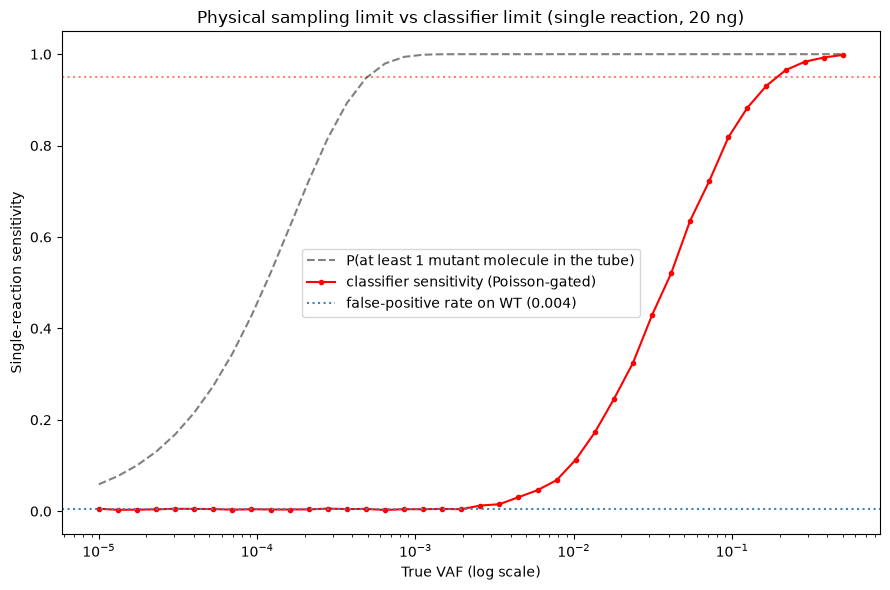

In [15]:
#15: Physical sampling limit (Poisson)
"""A reaction can only detect a mutant allele if at least one mutant molecule is physically in the tube.
With 20 ng of DNA (6.6 pg per diploid genome) there are ~6061 alleles per reaction, so the number of mutant
molecules in a reaction is Poisson distributed with mean = VAF x total alleles."""

NG_PER_REACTION = 20
PG_PER_GENOME = 6.6
ALLELES_PER_GENOME = 2
total_alleles = (NG_PER_REACTION * 1000 / PG_PER_GENOME) * ALLELES_PER_GENOME
print(f"Total alleles per reaction: {total_alleles:.0f}")

N_REACTIONS = 3000
vaf_grid = np.logspace(-5, np.log10(0.5), 40)
rng = np.random.default_rng(99)

rows = []
for vaf_value in vaf_grid:
    vaf = np.full(N_REACTIONS, vaf_value)
    dna_conc = _generate_concentration(N_REACTIONS, conc_min=PARAMS["conc_min"], conc_max=PARAMS["conc_max"], rng=rng)
    signal = _generate_delta_ct_signal(vaf, PARAMS["pure_mutant_delta_ct"], PARAMS["eff"], PARAMS["signal_noise_std"], N_REACTIONS, rng)
    background = _generate_delta_ct_background(
        N_REACTIONS, dna_conc, PARAMS["background_mean"], PARAMS["background_std"], PARAMS["conc_slope"], PARAMS["conc_ref"], rng
    )
    #draw the number of mutant molecules actually present, signal exists only if there is at least one
    has_molecule = rng.poisson(vaf_value * total_alleles, size=N_REACTIONS) >= 1
    gated = np.minimum(np.where(has_molecule, signal, np.inf), background)
    rows.append({
        "vaf": vaf_value,
        "p_molecule_present": 1 - np.exp(-vaf_value * total_alleles),
        "sens_gated": (classify(gated) == "Mut").mean(),
    })
poisson_df = pd.DataFrame(rows)

#false-positive rate of the classifier on true WT reactions (background only, no mutant signal at all)
N_WT = 20000
wt_conc = _generate_concentration(N_WT, conc_min=PARAMS["conc_min"], conc_max=PARAMS["conc_max"], rng=rng)
wt_background = _generate_delta_ct_background(
    N_WT, wt_conc, PARAMS["background_mean"], PARAMS["background_std"], PARAMS["conc_slope"], PARAMS["conc_ref"], rng
)
fp_rate = (classify(wt_background) == "Mut").mean()
print(f"False-positive rate on true WT reactions (n={N_WT}): {fp_rate:.4f}")

def first_vaf_reaching(column, level=0.95):
    hit = poisson_df[poisson_df[column] >= level]
    return hit["vaf"].min() if len(hit) else None

for label, column in [("molecule present in the tube (physical ceiling)", "p_molecule_present"),
                      ("classifier, Poisson-gated", "sens_gated")]:
    v = first_vaf_reaching(column)
    print(f"Lowest VAF with 95% single-reaction sensitivity, {label}: {v:.5f}" if v else f"{label}: not reached")

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(poisson_df["vaf"], poisson_df["p_molecule_present"], color="gray", linestyle="--", label="P(at least 1 mutant molecule in the tube)")
ax.plot(poisson_df["vaf"], poisson_df["sens_gated"], color="red", marker="o", markersize=3, label="classifier sensitivity (Poisson-gated)")
ax.axhline(fp_rate, color="steelblue", linestyle=":", label=f"false-positive rate on WT ({fp_rate:.3f})")
ax.axhline(0.95, color="red", linestyle=":", alpha=0.5)
ax.set_xscale("log")
ax.set_xlabel("True VAF (log scale)")
ax.set_ylabel("Single-reaction sensitivity")
ax.set_ylim(-0.05, 1.05)
ax.set_title(f"Physical sampling limit vs classifier limit (single reaction, {NG_PER_REACTION} ng)")
ax.legend()
plt.tight_layout()
plt.savefig("poisson_sampling_limit.png", dpi=150)
print("\nSaved as poisson_sampling_limit.png")
plt.show()

Bootstrap GMM refits: 999/1000 resamples recover a minority Mut component
95% CI over those stable resamples:
  Mutant mean: original 2.121, 95% CI [1.894, 2.436]
  WT mean: original 15.025, 95% CI [14.921, 15.157]
  Boundary: original 6.122, 95% CI [5.794, 6.512]

Saved as gmm_boundary_bootstrap.png


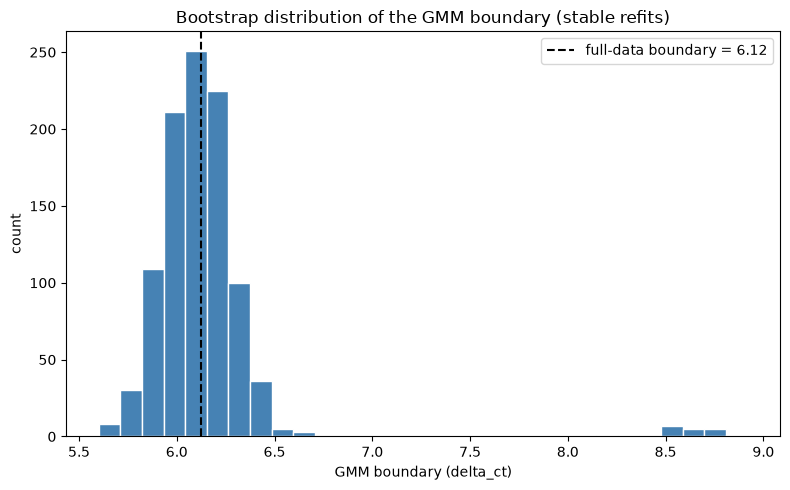

Held out fold 1: refit Mut mean = 2.00, WT mean = 15.02, boundary = 6.00, Mut weight = 0.10, stable = True
Held out fold 2: refit Mut mean = 2.16, WT mean = 15.03, boundary = 6.18, Mut weight = 0.10, stable = True
Held out fold 3: refit Mut mean = 2.10, WT mean = 15.02, boundary = 6.05, Mut weight = 0.10, stable = True
Held out fold 4: refit Mut mean = 2.13, WT mean = 15.02, boundary = 6.08, Mut weight = 0.10, stable = True
Held out fold 5: refit Mut mean = 2.11, WT mean = 15.01, boundary = 6.08, Mut weight = 0.10, stable = True

Cross-validation: disagreements with full-data GMM = 5, accuracy vs true_label = 0.9938
sample_id  delta_ct true_label gmm_label gmm_label_cv
 SYN-2274  6.015766         WT       Mut           WT
 SYN-3360  6.081954         WT       Mut           WT
 SYN-0037  6.106089         WT       Mut           WT
 SYN-4838  6.108689         WT       Mut           WT
 SYN-4624  6.113504         WT       Mut           WT

Confusion matrix (rows=test call, cols=true genotyp

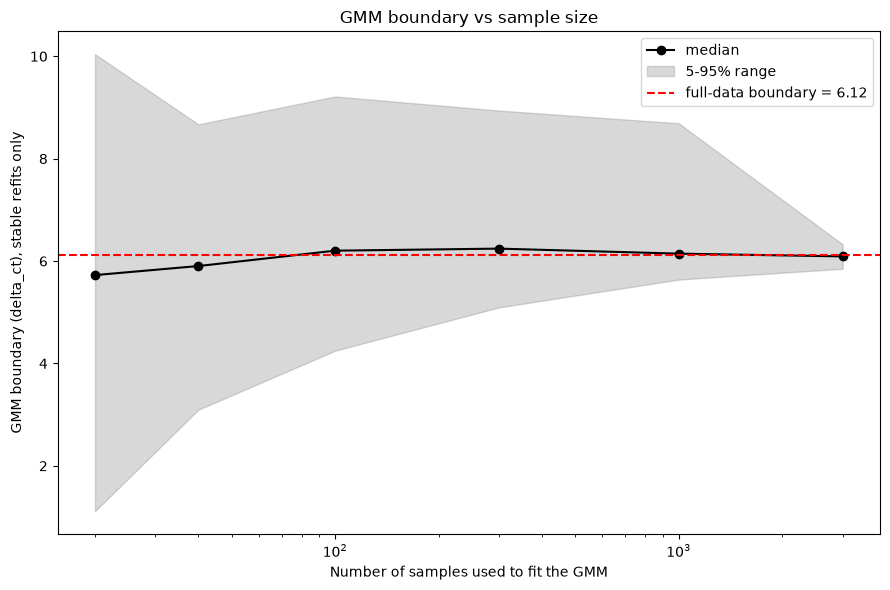

In [16]:
#16: GMM robustness (bootstrap, cross-validation, sample size)

def fit_gmm_params(x):
    #Fit a 2-component GMM
    g = GaussianMixture(n_components=2, random_state=42).fit(x)
    m = np.argmin(g.means_.ravel())
    mu_m, mu_w = g.means_.ravel()[m], g.means_.ravel()[1 - m]
    xs = np.linspace(mu_m, mu_w, 10000)
    d_m = g.weights_[m] * norm.pdf(xs, mu_m, np.sqrt(g.covariances_.ravel()[m]))
    d_w = g.weights_[1 - m] * norm.pdf(xs, mu_w, np.sqrt(g.covariances_.ravel()[1 - m]))
    return g, m, mu_m, mu_w, xs[np.argmin(np.abs(d_m - d_w))], g.weights_[m]

"""a refit is "stable" if the lower component is still the minority (Mut weight < 0.5);
otherwise the 2-component split has latched onto the WT tail instead of the Mut group.
Here the lower component must also sit on the Mut side of the full-data boundary: at low prevalence the plain GMM can
latch onto the WT tail with a minority weight, and the weight criterion alone would miss that"""
def is_stable(mu_m, w_m):
    return (w_m < 0.5) & (mu_m < gmm_boundary)

#Bootstrap: resample samples, refit the GMM each time, record parameters + boundary
n_bootstrap = 1000
rng = np.random.default_rng(42)
boot = []
for _ in range(n_bootstrap):
    idx = rng.integers(0, len(X), len(X))
    xb = X[idx]
    if len(np.unique(xb)) < 4:
        continue
    g, m, mu_m, mu_w, b, w_m = fit_gmm_params(xb)
    boot.append((mu_m, mu_w, b, w_m))
boot = np.array(boot)

stable = is_stable(boot[:, 0], boot[:, 3])
print(f"Bootstrap GMM refits: {stable.sum()}/{len(boot)} resamples recover a minority Mut component")
print("95% CI over those stable resamples:")
for name, col, orig in [("Mutant mean", 0, mut_mean), ("WT mean", 1, wt_mean), ("Boundary", 2, gmm_boundary)]:
    lo, hi = np.percentile(boot[stable, col], [2.5, 97.5])
    print(f"  {name}: original {orig:.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")

#plotting bootstrap distribution of the boundary
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(boot[stable, 2], bins=30, color="steelblue", edgecolor="white")
ax.axvline(gmm_boundary, color="black", linestyle="--", label=f"full-data boundary = {gmm_boundary:.2f}")
ax.set_xlabel("GMM boundary (delta_ct)")
ax.set_ylabel("count")
ax.set_title("Bootstrap distribution of the GMM boundary (stable refits)")
ax.legend()
plt.tight_layout()
plt.savefig("gmm_boundary_bootstrap.png", dpi=150)
print("\nSaved as gmm_boundary_bootstrap.png")
plt.show()


#GMM cross-validation (stratified 5-fold)
"""Refitting the GMM without a fold of samples, then classify that fold with the refitted model. 
Samples here are independent, so folds replace patients."""
y_bin = df["true_label_binary"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_labels = np.empty(len(df), dtype=object)
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y_bin), start=1):
    g, m, mu_m, mu_w, b, w_m = fit_gmm_params(X[train_idx])
    pred = g.predict(X[test_idx])
    cv_labels[test_idx] = np.where(pred == m, "Mut", "WT")
    print(f"Held out fold {fold}: refit Mut mean = {mu_m:.2f}, WT mean = {mu_w:.2f}, "
          f"boundary = {b:.2f}, Mut weight = {w_m:.2f}, stable = {bool(is_stable(mu_m, w_m))}")
df["gmm_label_cv"] = cv_labels

n_dis = (df["gmm_label"] != df["gmm_label_cv"]).sum()
print(f"\nCross-validation: disagreements with full-data GMM = {n_dis}, accuracy vs true_label = {accuracy_score(df['true_label'], df['gmm_label_cv']):.4f}")
if n_dis > 0:
    print(df.loc[df["gmm_label"] != df["gmm_label_cv"], ["sample_id", "delta_ct", "true_label", "gmm_label", "gmm_label_cv"]]
          .sort_values("delta_ct").to_string(index=False))

print("\nConfusion matrix (rows=test call, cols=true genotype), cross-validated labels:")
cm = confusion_matrix(df["true_label"], df["gmm_label_cv"], labels=["Mut", "WT"]).T
print(pd.DataFrame(cm, index=["call Mut", "call WT"], columns=["true Mut", "true WT"]))


#Sample size: refit the GMM on random subsets of increasing size
SAMPLE_SIZES = [20, 40, 100, 300, 1000, 3000]
N_SUBSETS = 200
rng = np.random.default_rng(7)
rows = []
for n in SAMPLE_SIZES:
    for _ in range(N_SUBSETS):
        xs_sub = X[rng.choice(len(X), size=n, replace=False)]
        if len(np.unique(xs_sub)) < 4:
            continue
        g, m, mu_m, mu_w, b, w_m = fit_gmm_params(xs_sub)
        rows.append({"n": n, "boundary": b, "stable": bool(is_stable(mu_m, w_m))})
size_df = pd.DataFrame(rows)

size_summary = size_df.groupby("n").apply(lambda s: pd.Series({
    "fraction stable": s["stable"].mean(),
    "boundary median (stable)": s.loc[s["stable"], "boundary"].median(),
    "boundary 5%": s.loc[s["stable"], "boundary"].quantile(0.05),
    "boundary 95%": s.loc[s["stable"], "boundary"].quantile(0.95),
})).round(3)
print(f"\nSample-size sweep ({N_SUBSETS} random subsets per size, mutant prevalence {(df['true_label'] == 'Mut').mean():.0%}):")
print(size_summary.to_string())

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(size_summary.index, size_summary["boundary median (stable)"], "o-", color="black", label="median")
ax.fill_between(size_summary.index, size_summary["boundary 5%"], size_summary["boundary 95%"], color="gray", alpha=0.3, label="5-95% range")
ax.axhline(gmm_boundary, color="red", linestyle="--", label=f"full-data boundary = {gmm_boundary:.2f}")
ax.set_xscale("log")
ax.set_xlabel("Number of samples used to fit the GMM")
ax.set_ylabel("GMM boundary (delta_ct), stable refits only")
ax.set_title("GMM boundary vs sample size")
ax.legend()
plt.tight_layout()
plt.savefig("gmm_sample_size_boundary.png", dpi=150)
print("\nSaved as gmm_sample_size_boundary.png")
plt.show()

K-means clustering (k=2):
Centers (Mut, WT): [ 4.245 15.431]
Silhouette score: 0.6594

K-means vs true genotype:
Accuracy: 0.9420

Confusion matrix (rows=true, cols=predicted), labels=[Mut, WT]:
[[ 493    0]
 [ 290 4217]]

Classification report:
              precision    recall  f1-score   support

         Mut       0.63      1.00      0.77       493
          WT       1.00      0.94      0.97      4507

    accuracy                           0.94      5000
   macro avg       0.81      0.97      0.87      5000
weighted avg       0.96      0.94      0.95      5000

K-means decision boundary: delta_ct = 9.838
Disagreements GMM vs K-means: 264 of 5000

Silhouette score sweep:
k=2: silhouette=0.6594
k=3: silhouette=0.5756
k=4: silhouette=0.5536
k=5: silhouette=0.5455
Best k according to silhouette score: 2

Saved as kmeans_cluster_view_synthetic.png


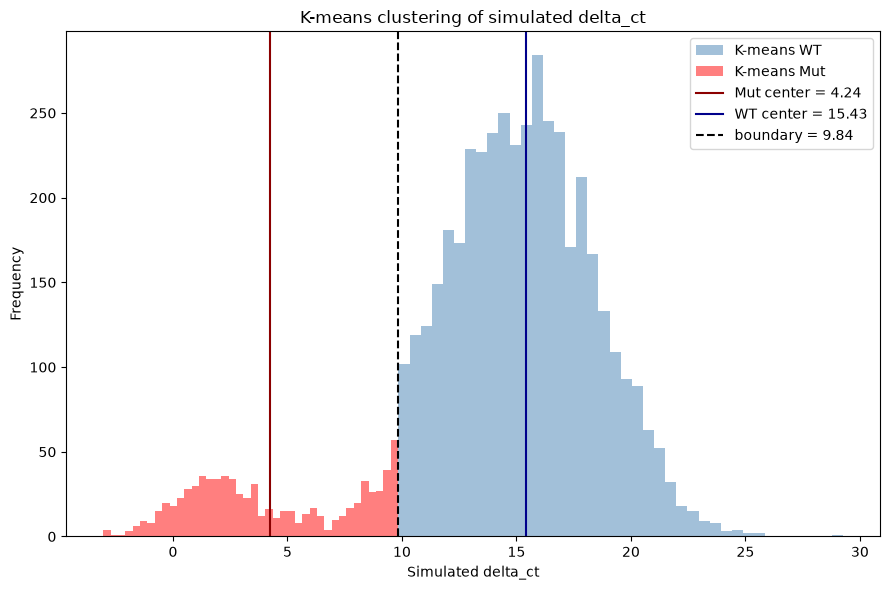

In [17]:
#17: K-means clustering on delta_ct

X_km = df["delta_ct"].values.reshape(-1, 1)

#K-means with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
km_raw = kmeans.fit_predict(X_km)
centers = kmeans.cluster_centers_.ravel()

#the mutant cluster is the one with the lower delta_ct center
mut_cluster = np.argmin(centers)
df["kmeans_label"] = np.where(km_raw == mut_cluster, "Mut", "WT")

print("K-means clustering (k=2):")
print("Centers (Mut, WT):", np.round([centers[mut_cluster], centers[1 - mut_cluster]], 3))
print(f"Silhouette score: {silhouette_score(X_km, km_raw):.4f}")

#K-means vs true genotype
print("\nK-means vs true genotype:")
print(f"Accuracy: {accuracy_score(df['true_label'], df['kmeans_label']):.4f}")
print("\nConfusion matrix (rows=true, cols=predicted), labels=[Mut, WT]:")
print(confusion_matrix(df["true_label"], df["kmeans_label"], labels=["Mut", "WT"]))
print("\nClassification report:")
print(classification_report(df["true_label"], df["kmeans_label"]))

#decision boundary
kmeans_boundary = (centers[mut_cluster] + centers[1 - mut_cluster]) / 2
print(f"K-means decision boundary: delta_ct = {kmeans_boundary:.3f}")


n_disagree = (df["gmm_label"] != df["kmeans_label"]).sum()
print(f"Disagreements GMM vs K-means: {n_disagree} of {len(df)}")


#Silhouette score sweep, k=2 to 5
print("\nSilhouette score sweep:")
sil_scores = []
for k in range(2, 6):
    labels_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_km)
    sil_scores.append(silhouette_score(X_km, labels_k))
    print(f"k={k}: silhouette={sil_scores[-1]:.4f}")
print(f"Best k according to silhouette score: {np.argmax(sil_scores) + 2}")


#Plot: delta_ct distribution colored by K-means label, with centers and boundary
fig, ax = plt.subplots(figsize=(9, 6))
is_km_wt = df["kmeans_label"] == "WT"
ax.hist(df.loc[is_km_wt, "delta_ct"], bins=40, alpha=0.5, color="steelblue", label="K-means WT")
ax.hist(df.loc[~is_km_wt, "delta_ct"], bins=40, alpha=0.5, color="red", label="K-means Mut")
ax.axvline(centers[mut_cluster], color="darkred", linestyle="-", label=f"Mut center = {centers[mut_cluster]:.2f}")
ax.axvline(centers[1 - mut_cluster], color="darkblue", linestyle="-", label=f"WT center = {centers[1 - mut_cluster]:.2f}")
ax.axvline(kmeans_boundary, color="black", linestyle="--", label=f"boundary = {kmeans_boundary:.2f}")
ax.set_xlabel("Simulated delta_ct")
ax.set_ylabel("Frequency")
ax.set_title("K-means clustering of simulated delta_ct")
ax.legend()
plt.tight_layout()
plt.savefig("kmeans_cluster_view_synthetic.png", dpi=150)
print("\nSaved as kmeans_cluster_view_synthetic.png")
plt.show()

Logistic regression, trained on train split:
Coefficients (ct_wt, ct_mut): -1.8163, 1.8066
Coefficient ratio (ct_mut / ct_wt): -0.9946

Test set size: 1500

Logistic regression accuracy, held-out test set (n=1500): 0.9947
Logistic regression accuracy, full dataset (n=5000, includes training samples): 0.9946

Confusion matrix (rows=true, cols=predicted), labels=[Mut, WT]:
[[ 145    3]
 [   5 1347]]

Classification report:
              precision    recall  f1-score   support

         Mut       0.97      0.98      0.97       148
          WT       1.00      1.00      1.00      1352

    accuracy                           0.99      1500
   macro avg       0.98      0.99      0.99      1500
weighted avg       0.99      0.99      0.99      1500


Decision boundary equation: Ct_mut = 5.454 + 1.005 x Ct_wt

Saved as logreg_decision_boundary_synthetic.png


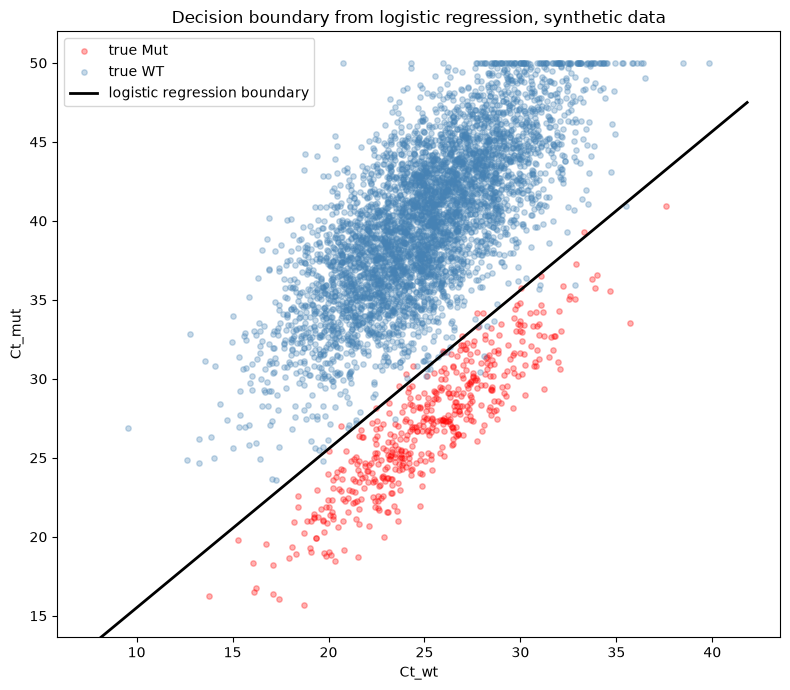

In [18]:
#18: Logistic Regression

X = df[["ct_wt", "ct_mut"]].values
y = df["true_label"].values

#Stratified split: preserves the class balance set in PARAMS in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

logreg = LogisticRegression(C=1.0)
logreg.fit(X_train, y_train)

coef_wt, coef_mut = logreg.coef_.ravel()
print("Logistic regression, trained on train split:")
print(f"Coefficients (ct_wt, ct_mut): {coef_wt:.4f}, {coef_mut:.4f}")
print(f"Coefficient ratio (ct_mut / ct_wt): {coef_mut / coef_wt:.4f}")
print(f"\nTest set size: {len(y_test)}")

y_pred = logreg.predict(X_test)

#Logistic regression accuracy
acc_test = accuracy_score(y_test, y_pred)
print(f"\nLogistic regression accuracy, held-out test set (n={len(y_test)}): {acc_test:.4f}")

#Accuracy on the whole dataset, directly comparable to the GMM and K-means accuracies (which use all samples)
y_pred_all = logreg.predict(df[["ct_wt", "ct_mut"]].values)
acc_all = accuracy_score(df["true_label"], y_pred_all)
print(f"Logistic regression accuracy, full dataset (n={len(df)}, includes training samples): {acc_all:.4f}")


print("\nConfusion matrix (rows=true, cols=predicted), labels=[Mut, WT]:")
print(confusion_matrix(y_test, y_pred, labels=["Mut", "WT"]))
print("\nClassification report:")
print(classification_report(y_test, y_pred))


#Logistic regression decision boundary in the (ct_wt, ct_mut) plane
"""The boundary is the line where the model's decision function is 0 (P(Mut) = 0.5):
intercept + coef_wt * ct_wt + coef_mut * ct_mut = 0"""
intercept = logreg.intercept_[0]
print(f"\nDecision boundary equation: Ct_mut = {-intercept/coef_mut:.3f} + {-coef_wt/coef_mut:.3f} x Ct_wt")

fig, ax = plt.subplots(figsize=(8, 7))
colors = {"Mut": "red", "WT": "steelblue"}
for label, group in df.groupby("true_label"):
    ax.scatter(group["ct_wt"], group["ct_mut"], color=colors[label], label=f"true {label}", alpha=0.3, s=15)

ct_wt_line = np.linspace(df["ct_wt"].min() - 2, df["ct_wt"].max() + 2, 100)
ct_mut_line = -(intercept + coef_wt * ct_wt_line) / coef_mut
ax.plot(ct_wt_line, ct_mut_line, color="black", linewidth=2, label="logistic regression boundary")

ax.set_ylim(df["ct_mut"].min() - 2, df["ct_mut"].max() + 2)
ax.set_xlabel("Ct_wt")
ax.set_ylabel("Ct_mut")
ax.set_title("Decision boundary from logistic regression, synthetic data")
ax.legend()
plt.tight_layout()
plt.savefig("logreg_decision_boundary_synthetic.png", dpi=150)
print("\nSaved as logreg_decision_boundary_synthetic.png")
plt.show()

stratified 5-fold cross-validation:
ROC-AUC: mean=0.9996, std=0.0002, per-fold=[0.9993 0.9998 0.9997 0.9998 0.9996]
PR-AUC (average precision): mean=0.9963, std=0.0021, per-fold=[0.9923 0.9984 0.9969 0.9976 0.9963]

Overall PR-AUC (out-of-fold): 0.9962
Class prevalence (no-skill baseline for PR): 0.0986

Saved as precision_recall_curve.png


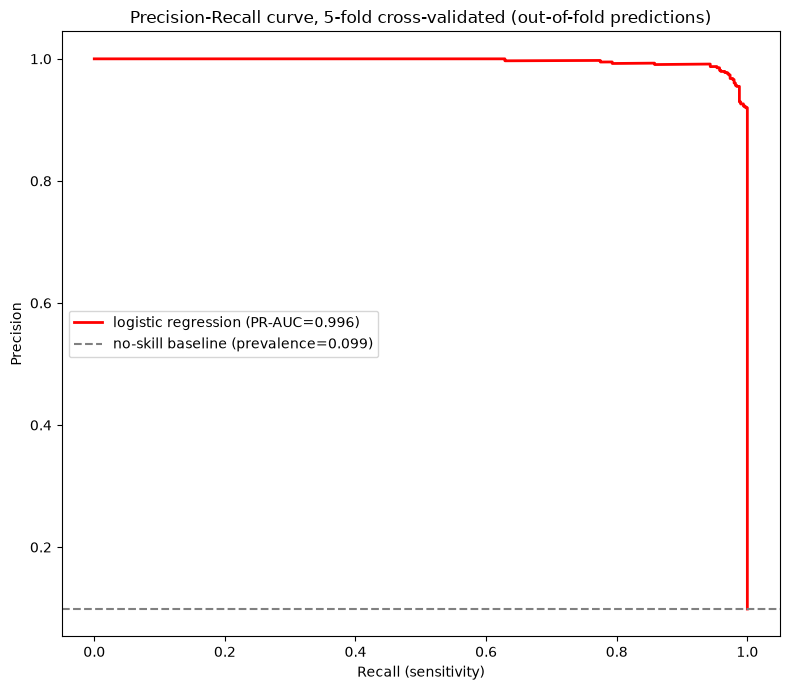


Overall ROC-AUC (out-of-fold): 0.9996

Saved as roc_curve_synthetic.png


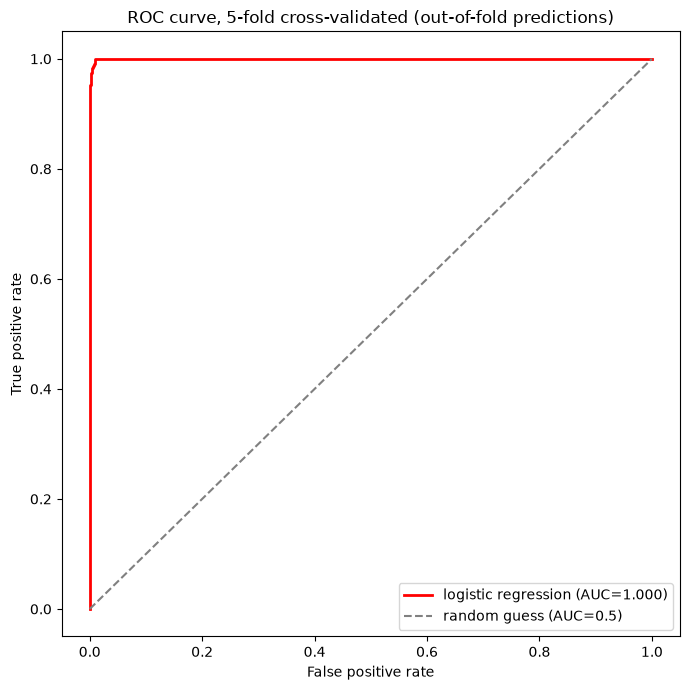

In [19]:
#19: Logistic regression (Precision-Recall, ROC-AUC, repeated stratified k-fold cross-validation)
"""Stratified k-fold to ensure that each fold maintains the class balance set in PARAMS"""

X = df[["ct_wt", "ct_mut"]].values
y = df["true_label_binary"].values

logreg = LogisticRegression(C=1.0)
N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

#Cross-validated ROC AUC and PR AUC scores
roc_scores = cross_val_score(logreg, X, y, cv=cv, scoring="roc_auc")
pr_scores = cross_val_score(logreg, X, y, cv=cv, scoring="average_precision")

print(f"stratified {N_SPLITS}-fold cross-validation:")
print(f"ROC-AUC: mean={roc_scores.mean():.4f}, std={roc_scores.std():.4f}, per-fold={np.round(roc_scores, 4)}")
print(f"PR-AUC (average precision): mean={pr_scores.mean():.4f}, std={pr_scores.std():.4f}, per-fold={np.round(pr_scores, 4)}")


#Out-of-fold predictions for the entire dataset
"""For each sample, the prediction is made by the classifier that 
was trained on the folds that did not include that sample. 
Then we constructed a single precision-recall curve that reflects the classifier's performance on the entire dataset."""

y_proba_oof = cross_val_predict(logreg, X, y, cv=cv, method="predict_proba")[:, 1]
precision, recall, thresholds = precision_recall_curve(y, y_proba_oof)
avg_precision = average_precision_score(y, y_proba_oof)
baseline = y.mean()  #Mutant class prevalence - the "no-skill" baseline for PR (precision if we randomly guessed for each sample)

print(f"\nOverall PR-AUC (out-of-fold): {avg_precision:.4f}")
print(f"Class prevalence (no-skill baseline for PR): {baseline:.4f}")

#Plotting the precision-recall curve
fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(recall, precision, color="red", linewidth=2, label=f"logistic regression (PR-AUC={avg_precision:.3f})")
ax.axhline(baseline, color="gray", linestyle="--", label=f"no-skill baseline (prevalence={baseline:.3f})")
ax.set_xlabel("Recall (sensitivity)")
ax.set_ylabel("Precision")
ax.set_title(f"Precision-Recall curve, {N_SPLITS}-fold cross-validated (out-of-fold predictions)")
ax.legend()
plt.tight_layout()
plt.savefig("precision_recall_curve.png", dpi=150)
print("\nSaved as precision_recall_curve.png")
plt.show()

#ROC curve from the out-of-fold predictions
fpr, tpr, _ = roc_curve(y, y_proba_oof)
roc_auc = roc_auc_score(y, y_proba_oof)
print(f"\nOverall ROC-AUC (out-of-fold): {roc_auc:.4f}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(fpr, tpr, color="red", linewidth=2, label=f"logistic regression (AUC={roc_auc:.3f})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="random guess (AUC=0.5)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title(f"ROC curve, {N_SPLITS}-fold cross-validated (out-of-fold predictions)")
ax.legend()
plt.tight_layout()
plt.savefig("roc_curve_synthetic.png", dpi=150)
print("\nSaved as roc_curve_synthetic.png")
plt.show()

Absolute thresholds: technical failure if Ct_wt >= 38; Mut if Ct_mut < 34, otherwise WT
Technical failures: 2 / 5000

Genotype call vs true label (before removing technical failures):
true genotype  Mut    WT
test call               
Mut            470   510
WT              23  3997

Decision boundaries, all methods (evaluated on the full dataset, n=5000):
             method                       boundary  misclassified  accuracy
                GMM               delta_ct = 6.122             36    0.9928
            K-means               delta_ct = 9.838            290    0.9420
Logistic regression Ct_mut = 5.454 + 1.005 x Ct_wt             27    0.9946

Saved as all_decision_boundaries_synthetic.png


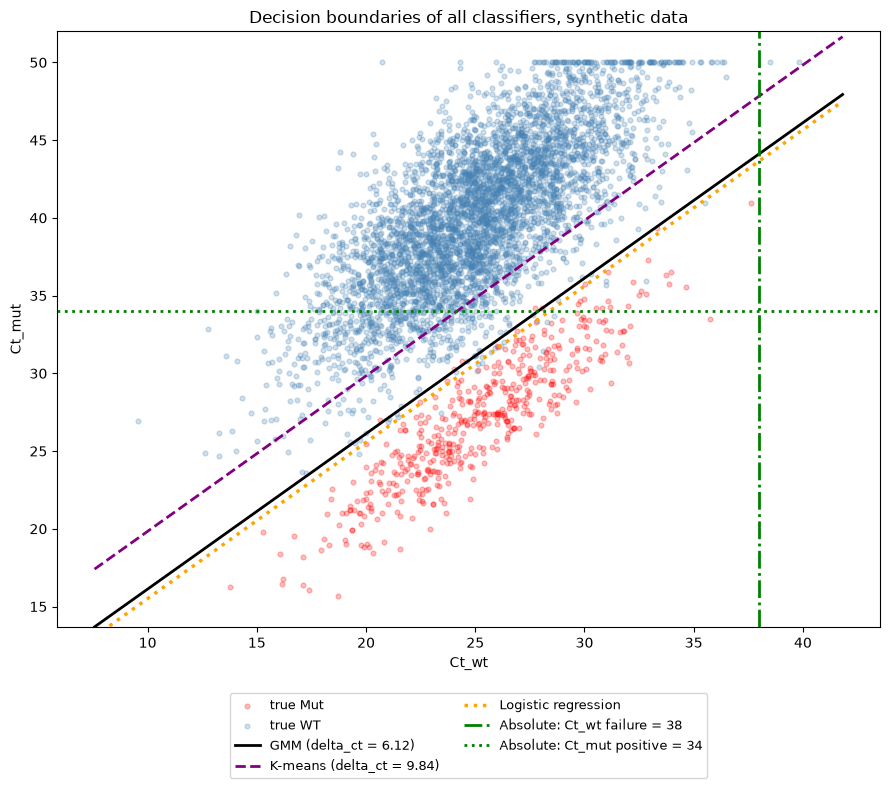

Saved as all_boundaries_delta_ct_synthetic.png


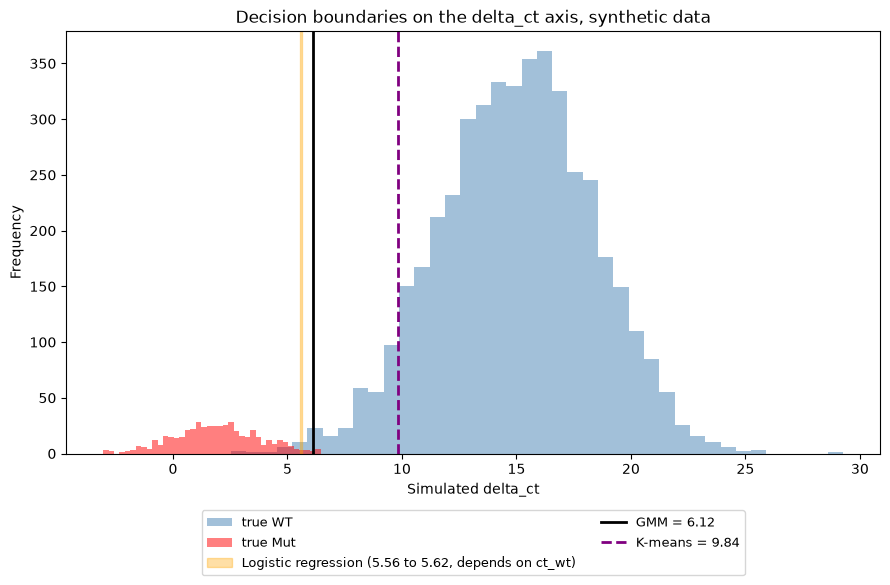

In [20]:
#20: All decision boundaries compared (GMM, K-means, logistic regression)

lr_pred_all = np.where(coef_wt * df["ct_wt"] + coef_mut * df["ct_mut"] + intercept > 0, "WT", "Mut")
#logreg.classes_ is ['Mut', 'WT'], so a positive decision function means WT

#absolute Ct thresholds, CT_WT_FAILURE already defined
CT_MUT_POSITIVE = 34.0   #Ct_mut < this means Mut, otherwise WT

df["absolute_call"] = np.where(df["ct_mut"] < CT_MUT_POSITIVE, "Mut", "WT")
df["absolute_label"] = np.where(df["technical_failure"], "Technical failure", df["absolute_call"])
df["absolute_wrong"] = df["absolute_label"] != df["true_label"]

print(f"Absolute thresholds: technical failure if Ct_wt >= {CT_WT_FAILURE:g}; Mut if Ct_mut < {CT_MUT_POSITIVE:g}, otherwise WT")
print(f"Technical failures: {df['technical_failure'].sum()} / {len(df)}")
print("\nGenotype call vs true label (before removing technical failures):")
print(pd.crosstab(df["absolute_call"], df["true_label"], rownames=["test call"], colnames=["true genotype"]))
print()

boundary_summary = pd.DataFrame({
    "method": ["GMM", "K-means", "Logistic regression"],
    "boundary": [
        f"delta_ct = {gmm_boundary:.3f}",
        f"delta_ct = {kmeans_boundary:.3f}",
        f"Ct_mut = {-intercept/coef_mut:.3f} + {-coef_wt/coef_mut:.3f} x Ct_wt",
    ],
    "misclassified": [
        (df["gmm_label"] != df["true_label"]).sum(),
        (df["kmeans_label"] != df["true_label"]).sum(),
        (lr_pred_all != df["true_label"]).sum(),
    ],
})
boundary_summary["accuracy"] = 1 - boundary_summary["misclassified"] / len(df)
print("Decision boundaries, all methods (evaluated on the full dataset, n={}):".format(len(df)))
print(boundary_summary.to_string(index=False))

#all boundaries in the ct_wt and ct_mut space
fig, ax = plt.subplots(figsize=(9, 8))
colors = {"Mut": "red", "WT": "steelblue"}
for label, group in df.groupby("true_label"):
    ax.scatter(group["ct_wt"], group["ct_mut"], color=colors[label], label=f"true {label}", alpha=0.25, s=12)

ct_wt_line = np.linspace(df["ct_wt"].min() - 2, df["ct_wt"].max() + 2, 100)
ax.plot(ct_wt_line, ct_wt_line + gmm_boundary, color="black", linestyle="-", linewidth=2,
        label=f"GMM (delta_ct = {gmm_boundary:.2f})")
ax.plot(ct_wt_line, ct_wt_line + kmeans_boundary, color="purple", linestyle="--", linewidth=2,
        label=f"K-means (delta_ct = {kmeans_boundary:.2f})")
ax.plot(ct_wt_line, -(intercept + coef_wt * ct_wt_line) / coef_mut, color="orange", linestyle=":", linewidth=2.5,
        label="Logistic regression")
ax.axvline(CT_WT_FAILURE, color="green", linestyle="-.", linewidth=2, label=f"Absolute: Ct_wt failure = {CT_WT_FAILURE:g}")
ax.axhline(CT_MUT_POSITIVE, color="green", linestyle=":", linewidth=2, label=f"Absolute: Ct_mut positive = {CT_MUT_POSITIVE:g}")

ax.set_ylim(df["ct_mut"].min() - 2, df["ct_mut"].max() + 2)
ax.set_xlabel("Ct_wt")
ax.set_ylabel("Ct_mut")
ax.set_title("Decision boundaries of all classifiers, synthetic data")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig("all_decision_boundaries_synthetic.png", dpi=150, bbox_inches="tight")
print("\nSaved as all_decision_boundaries_synthetic.png")
plt.show()


#all boundaries on the delta_ct axis
a_lr = -intercept / coef_mut
b_lr = -coef_wt / coef_mut
ct_wt_lo, ct_wt_hi = np.percentile(df["ct_wt"], [5, 95]) #logistic regression boundary shown as a band covering the 5th-95th percentile of ct_wt
lr_thr_lo, lr_thr_hi = sorted([a_lr + (b_lr - 1) * ct_wt_lo, a_lr + (b_lr - 1) * ct_wt_hi])

fig, ax = plt.subplots(figsize=(9, 6))
is_wt = df["true_label"] == "WT"
ax.hist(df.loc[is_wt, "delta_ct"], bins=40, alpha=0.5, color="steelblue", label="true WT")
ax.hist(df.loc[~is_wt, "delta_ct"], bins=40, alpha=0.5, color="red", label="true Mut")
ax.axvspan(lr_thr_lo, lr_thr_hi, color="orange", alpha=0.35,
           label=f"Logistic regression ({lr_thr_lo:.2f} to {lr_thr_hi:.2f}, depends on ct_wt)")
ax.axvline(gmm_boundary, color="black", linestyle="-", linewidth=2, label=f"GMM = {gmm_boundary:.2f}")
ax.axvline(kmeans_boundary, color="purple", linestyle="--", linewidth=2, label=f"K-means = {kmeans_boundary:.2f}")
ax.set_xlabel("Simulated delta_ct")
ax.set_ylabel("Frequency")
ax.set_title("Decision boundaries on the delta_ct axis, synthetic data")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig("all_boundaries_delta_ct_synthetic.png", dpi=150, bbox_inches="tight")
print("Saved as all_boundaries_delta_ct_synthetic.png")
plt.show()

In [21]:

#21: Summary (all methods comparison and disagreements)

df["logreg_label"] = lr_pred_all
method_cols = {"GMM": "gmm_label", "K-means": "kmeans_label", "Logistic regression": "logreg_label"}
if "absolute_label" in df.columns:
    method_cols["Absolute Ct thresholds"] = "absolute_label"

#performance against the true label
rows = []
for name, col in method_cols.items():
    wrong = df[col] != df["true_label"]
    rows.append({
        "method": name,
        "accuracy": round(1 - wrong.mean(), 4),
        "Mut called WT": int(((df["true_label"] == "Mut") & (df[col] == "WT")).sum()),
        "WT called Mut": int(((df["true_label"] == "WT") & (df[col] == "Mut")).sum()),
        "technical failure": int((df[col] == "Technical failure").sum()),
    })
print(f"Performance vs true label (n={len(df)}: {(df['true_label'] == 'Mut').sum()} Mut, {(df['true_label'] == 'WT').sum()} WT):")
print(pd.DataFrame(rows).to_string(index=False))

#pairwise disagreements: number of samples on which two methods give different labels
names = list(method_cols)
disagree = pd.DataFrame(
    [[(df[method_cols[a]] != df[method_cols[b]]).sum() for b in names] for a in names],
    index=names, columns=names,
)
print("\nPairwise disagreements (number of samples with different labels):")
print(disagree.to_string())

#combinations of calls, and who is right when the methods split
label_cols = list(method_cols.values())
patterns = (
    df.groupby(label_cols)
    .agg(n=("delta_ct", "size"),
         true_Mut=("true_label", lambda s: (s == "Mut").sum()),
         delta_ct_min=("delta_ct", "min"), delta_ct_max=("delta_ct", "max"))
    .reset_index()
)
patterns.columns = list(method_cols) + list(patterns.columns[len(label_cols):])
all_agree = patterns[patterns[list(method_cols)].nunique(axis=1) == 1]
split = patterns[patterns[list(method_cols)].nunique(axis=1) > 1].sort_values("n", ascending=False)
print(f"\nAll methods agree on {all_agree['n'].sum()} of {len(df)} samples.")
print("Samples where the methods split (n = samples, true_Mut = how many of them are truly Mut):")
print(split.round(2).to_string(index=False) if len(split) else "none")

Performance vs true label (n=5000: 493 Mut, 4507 WT):
                method  accuracy  Mut called WT  WT called Mut  technical failure
                   GMM    0.9928              5             31                  0
               K-means    0.9420              0            290                  0
   Logistic regression    0.9946             12             15                  0
Absolute Ct thresholds    0.8930             23            510                  2

Pairwise disagreements (number of samples with different labels):
                        GMM  K-means  Logistic regression  Absolute Ct thresholds
GMM                       0      264                   23                     517
K-means                 264        0                  287                     485
Logistic regression      23      287                    0                     532
Absolute Ct thresholds  517      485                  532                       0

All methods agree on 4348 of 5000 samples.
Samples where t